
# Project 2 — Concrete Compressive Strength: Prediction from Mixture Composition and Age (Regression)

**Course:** DSC8307 Data Mining, Modeling and Analytics

**Student name:** NAMUYOMBA NAKACHWA EMILLY  
**Registration number:** S25M19/047  
**Access number:** B35963

---

## Executive summary

**Goal.** Predict concrete compressive strength (MPa) from the seven ingredient amounts and the curing age.

**What we did (following the Lecture 2 regression "Steps" flowchart)**
- **Exploration and preparation.** No missing values: the zeros mean "ingredient not used". The 25 duplicate rows are removed. Outliers (|Z| > 3) are genuine and kept. The 1,005 rows contain only **428 distinct mixes**, each tested at several ages, so **every split and cross-validation is grouped by mix**. A naive random split would overstate accuracy by up to 1.35 MPa.
- **Baseline.** Predicting the mean (35.3 MPa) gives RMSE ≈ 16.3 MPa and R² ≈ 0.
- **Linear models.** Least squares on the raw inputs reaches RMSE 10.6 MPa (R² 0.57) but **fails its assumption checks**. Following the flowchart's "No" arrow, we re-formulated it with log(age) and the water/cement and water/binder ratios (Abrams' law). That cut the error to **7.0 MPa (R² 0.81)**. Ridge, lasso and principal-components regression gave no further gain, and influence analysis showed that no single point drives the fit.
- **Non-linear models.** A 7-parameter **Abrams-law model fitted by non-linear least squares** reaches 7.5 MPa with physically meaningful parameters (slag is worth ≈0.74 kg of cement, fly ash ≈0.48). **Gradient boosting is the most accurate model**: grouped-CV RMSE **5.6 MPa (R² 0.88)**, test RMSE **4.5 MPa (R² 0.92)**. It beats the best linear model by ≈2 MPa (95% CI 1.1–3.1) and wins in 10 out of 10 re-drawn splits.
- **Where predictions are weakest.** For **very strong mixes**, which are under-estimated by 4–6 MPa on average. For **weak mixes**, which are *over*-estimated, the unsafe direction, especially by the linear models. For **slag-containing mixes**. And for **unusual mixes far from the training data**: the worst errors come from one very-low-water fly-ash mix, over-estimated by 19–30 MPa at every age.
- **Causality (Question 3): No.** The cement "effect" nearly doubles depending on which other ingredients are included (0.072 to 0.132 MPa per kg). Cement was substituted against slag and fly ash by design, the ingredients obey a mixture constraint (ρ = −0.80 between cement and everything else), and key lab conditions were not recorded. Only controlled experiments, backed by concrete science, can show what *changing* a mix will do.



##  Formulate the problem

**Engineering problem.** Compressive strength (in MPa) is the main quality property of concrete. Measuring it means casting specimens and crushing them after curing, sometimes for up to a year. A good model can **screen candidate mixes before lab testing**, saving time and money.

**Formulation choices (the four boxes next to "Formulate the problem")**
1. **Set of variables.** The 7 ingredients and age, plus engineered ratios suggested by concrete science (Step 4.7).
2. **Form of model.** Both linear and non-linear forms. Two pieces of domain knowledge guide them:
   - **Abrams' law** (Abrams, 1918): strength falls as the **water-to-cement ratio** rises, roughly $f_c = A / B^{w/c}$. The *ratio* matters, not each amount separately.
   - **Strength grows with age in a concave way.** It rises quickly in the first days and then levels off, so log(age) is a natural scale (Neville, 2011).
3. **Method of fitting.** Least squares and its variants (ridge, lasso, principal-components regression), non-linear least squares, and tree ensembles .
4. **Assumptions.** For least squares: a linear mean function, constant error variance, independent and roughly normal errors. These are checked , not just assumed.

**The assignment's three questions:** (1) explore and prepare the data and set a mean-prediction baseline; (2) compare linear and non-linear approaches, using residual analysis to find where predictions are weakest; (3) decide whether the cement–strength association proves what would happen if the mix were changed.

In [298]:

# Set-up and reproducibility
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from scipy.optimize import curve_fit
import sklearn
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pandas.api.types import is_numeric_dtype

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, KFold, cross_validate, cross_val_predict,
                                     GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path(".")          # Concrete_Data.csv is in the same folder as this notebook
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"statsmodels {statsmodels.__version__} | scipy {scipy.__version__}")

numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | statsmodels 0.14.6 | scipy 1.17.1


In [299]:

## Data selection: loading and renaming

concrete=pd.read_csv('Concrete_Data.csv')
concrete

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,79.986
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,61.887
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.053
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.296
...,...,...,...,...,...,...,...,...,...
1025,276.400,116.000,90.300,179.600,8.900,870.100,768.300,28,44.284
1026,322.200,0.000,115.600,196.000,10.400,817.900,813.400,28,31.179
1027,148.500,139.400,108.600,192.700,6.100,892.400,780.000,28,23.697
1028,159.100,186.700,0.000,175.600,11.300,989.600,788.900,28,32.768


In [300]:

original_names = concrete.columns.tolist()
COMPONENTS = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg"]
concrete.columns = COMPONENTS + ["age", "strength"]
print("Number of instances = %d" % concrete.shape[0])
print("Number of attributes = %d (8 predictors + 1 response)" % concrete.shape[1])
display(pd.DataFrame({"original column": original_names, "renamed to": concrete.columns}))
concrete.head()

Number of instances = 1030
Number of attributes = 9 (8 predictors + 1 response)


,original column,renamed to
0,Cement (kg in a m^3 mixture),cement
1,Blast Furnace Slag (kg in a m^3 mixture),slag
2,Fly Ash (kg in a m^3 mixture),fly_ash
3,Water (kg in a m^3 mixture),water
4,Superplasticizer (kg in a m^3 mixture),superplasticizer
5,Coarse Aggregate (kg in a m^3 mixture),coarse_agg
6,Fine Aggregate (kg in a m^3 mixture),fine_agg
7,Age (day),age
8,"Concrete compressive strength (MPa, megapascals)",strength


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,79.986
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,61.887
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,40.270
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,41.053
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,44.296


In [301]:

concrete.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [302]:

## Data exploration

### Summary statistics
for col in concrete.columns:
    if is_numeric_dtype(concrete[col]):
        print('%s:' % (col))
        print('\t Mean = %.2f' % concrete[col].mean())
        print('\t Standard deviation = %.2f' % concrete[col].std())
        print('\t Minimum = %.2f' % concrete[col].min())
        print('\t Maximum = %.2f' % concrete[col].max())

cement:
	 Mean = 281.17
	 Standard deviation = 104.51
	 Minimum = 102.00
	 Maximum = 540.00
slag:
	 Mean = 73.90
	 Standard deviation = 86.28
	 Minimum = 0.00
	 Maximum = 359.40
fly_ash:
	 Mean = 54.19
	 Standard deviation = 64.00
	 Minimum = 0.00
	 Maximum = 200.10
water:
	 Mean = 181.57
	 Standard deviation = 21.36
	 Minimum = 121.75
	 Maximum = 247.00
superplasticizer:
	 Mean = 6.20
	 Standard deviation = 5.97
	 Minimum = 0.00
	 Maximum = 32.20
coarse_agg:
	 Mean = 972.92
	 Standard deviation = 77.75
	 Minimum = 801.00
	 Maximum = 1145.00
fine_agg:
	 Mean = 773.58
	 Standard deviation = 80.18
	 Minimum = 594.00
	 Maximum = 992.60
age:
	 Mean = 45.66
	 Standard deviation = 63.17
	 Minimum = 1.00
	 Maximum = 365.00
strength:
	 Mean = 35.82
	 Standard deviation = 16.71
	 Minimum = 2.33
	 Maximum = 82.60


In [303]:

summary = concrete.describe().T
summary["n_zero"] = (concrete == 0).sum(); summary["% zero"] = 100 * summary["n_zero"] / len(concrete)
summary["skew"] = concrete.skew()
summary

,count,mean,std,min,25%,50%,75%,max,n_zero,% zero,skew
cement,"1,030.000",281.166,104.507,102.000,192.375,272.900,350.000,540.000,0,0.000,0.510
slag,"1,030.000",73.895,86.279,0.000,0.000,22.000,142.950,359.400,466,45.243,0.801
fly_ash,"1,030.000",54.187,63.996,0.000,0.000,0.000,118.270,200.100,566,54.951,0.537
water,"1,030.000",181.566,21.356,121.750,164.900,185.000,192.000,247.000,0,0.000,0.074
superplasticizer,"1,030.000",6.203,5.973,0.000,0.000,6.350,10.160,32.200,379,36.796,0.908
coarse_agg,"1,030.000",972.919,77.754,801.000,932.000,968.000,"1,029.400","1,145.000",0,0.000,-0.040
fine_agg,"1,030.000",773.579,80.175,594.000,730.950,779.510,824.000,992.600,0,0.000,-0.253
age,"1,030.000",45.662,63.170,1.000,7.000,28.000,56.000,365.000,0,0.000,3.269
strength,"1,030.000",35.818,16.706,2.332,23.707,34.443,46.136,82.599,0,0.000,0.417



**Interpretation**
- **Strength** ranges from 2.3 to 82.6 MPa (mean 35.8, sd 16.7) with almost no skewness (0.42). The response needs no transformation.
- **Age** ranges from 1 to 365 days but is **very right-skewed** (skew 3.27). Most specimens are young, with a long tail of old ones.
- **`slag` (45% zeros), `fly_ash` (55%) and `superplasticizer` (37%)** contain many zeros. These are **structural zeros**: the ingredient was simply not used in that mix. They are not missing values.
- `cement` (102–540 kg/m³) and `water` (122–247 kg/m³) vary a lot, which is promising for estimating their effects.



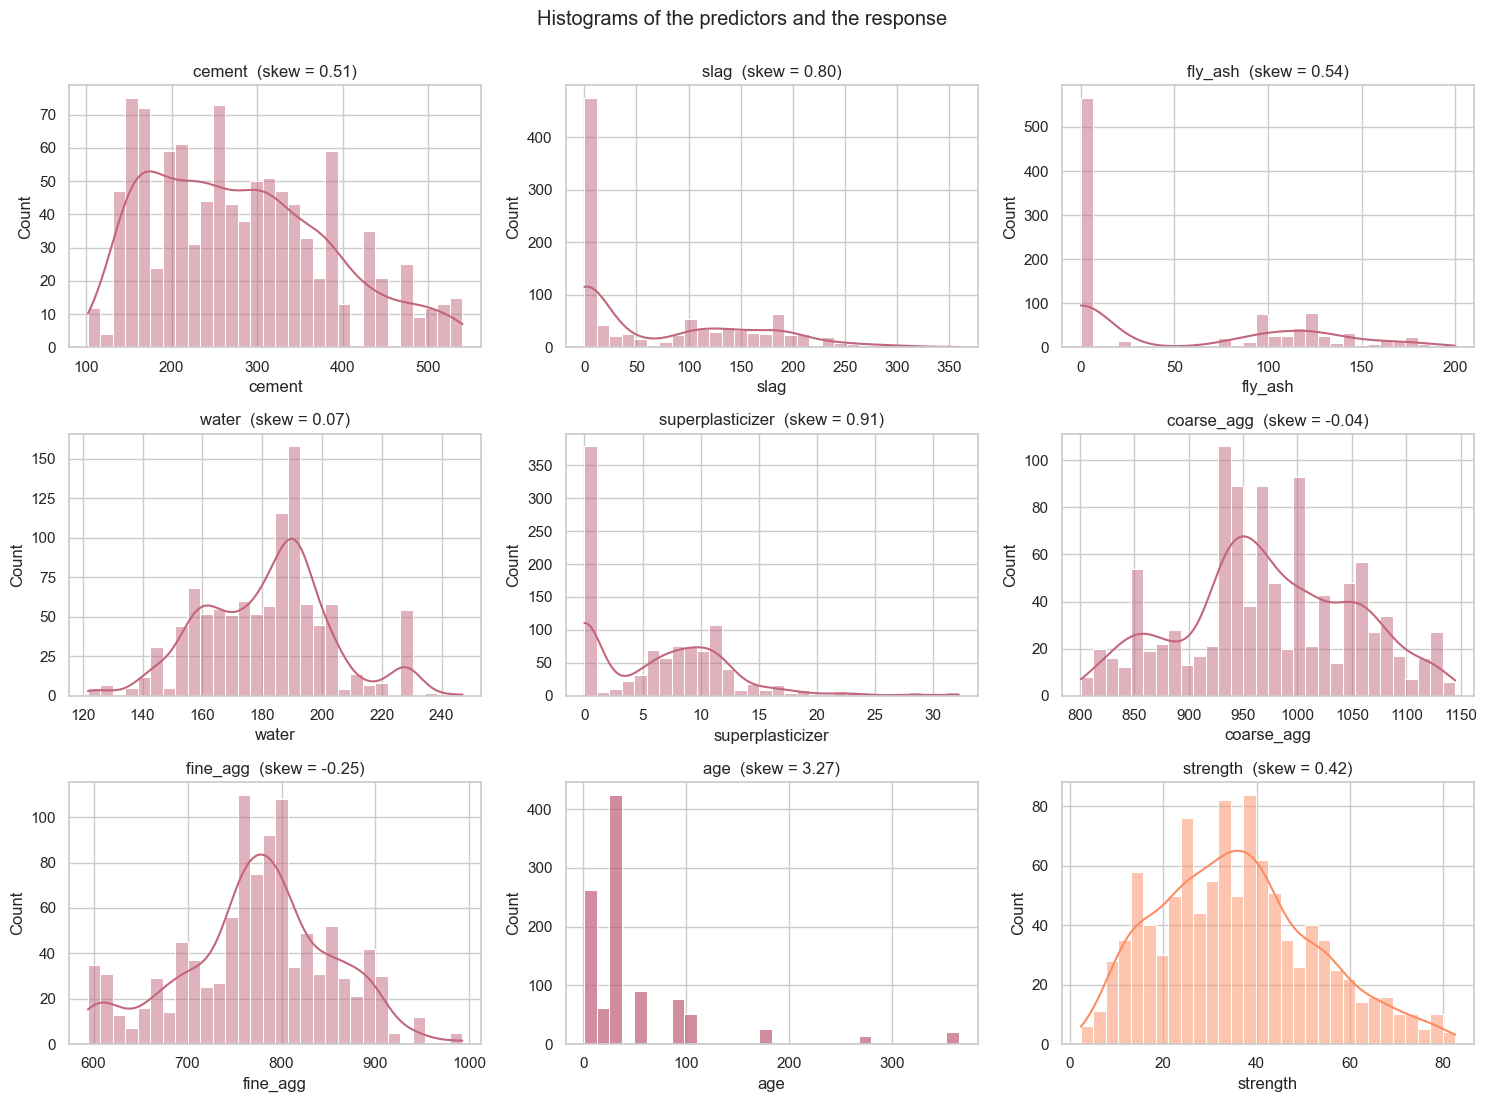

In [304]:


###  Distributions: histograms and boxplots
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), COMPONENTS + ["age", "strength"]):
    sns.histplot(concrete[c], bins=30, ax=ax, color="#c2667c" if c != "strength" else "#fc8d62", kde=c != "age")
    ax.set_title(f"{c}  (skew = {concrete[c].skew():.2f})")
plt.suptitle("Histograms of the predictors and the response", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "p2_distributions.png"); plt.show()

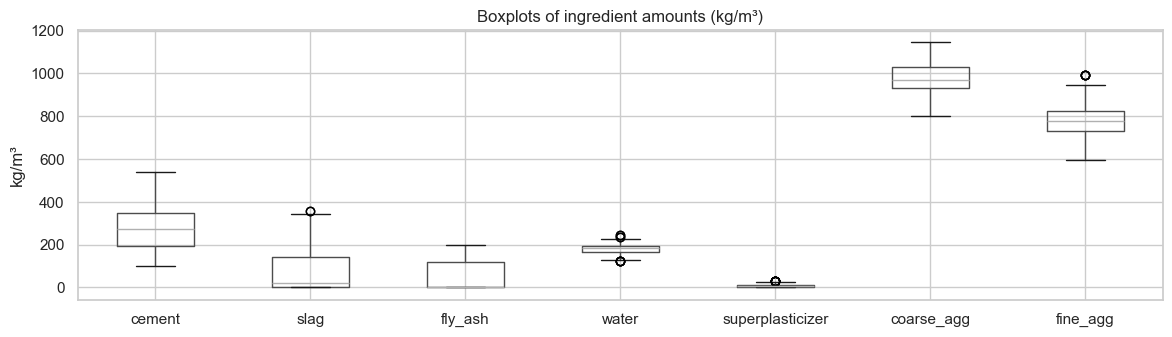

In [305]:

concrete[COMPONENTS].boxplot(figsize=(14, 3.5)); plt.title("Boxplots of ingredient amounts (kg/m³)"); plt.ylabel("kg/m³"); plt.show()


**Interpretation.**
 The spikes at zero for slag, fly ash and superplasticizer are clear in the histograms. Age has distinct spikes, because specimens are tested on a fixed schedule . The boxplots show a few high values for `water`, `superplasticizer`, `slag` and `fine_agg`; these are examined as possible outliers.


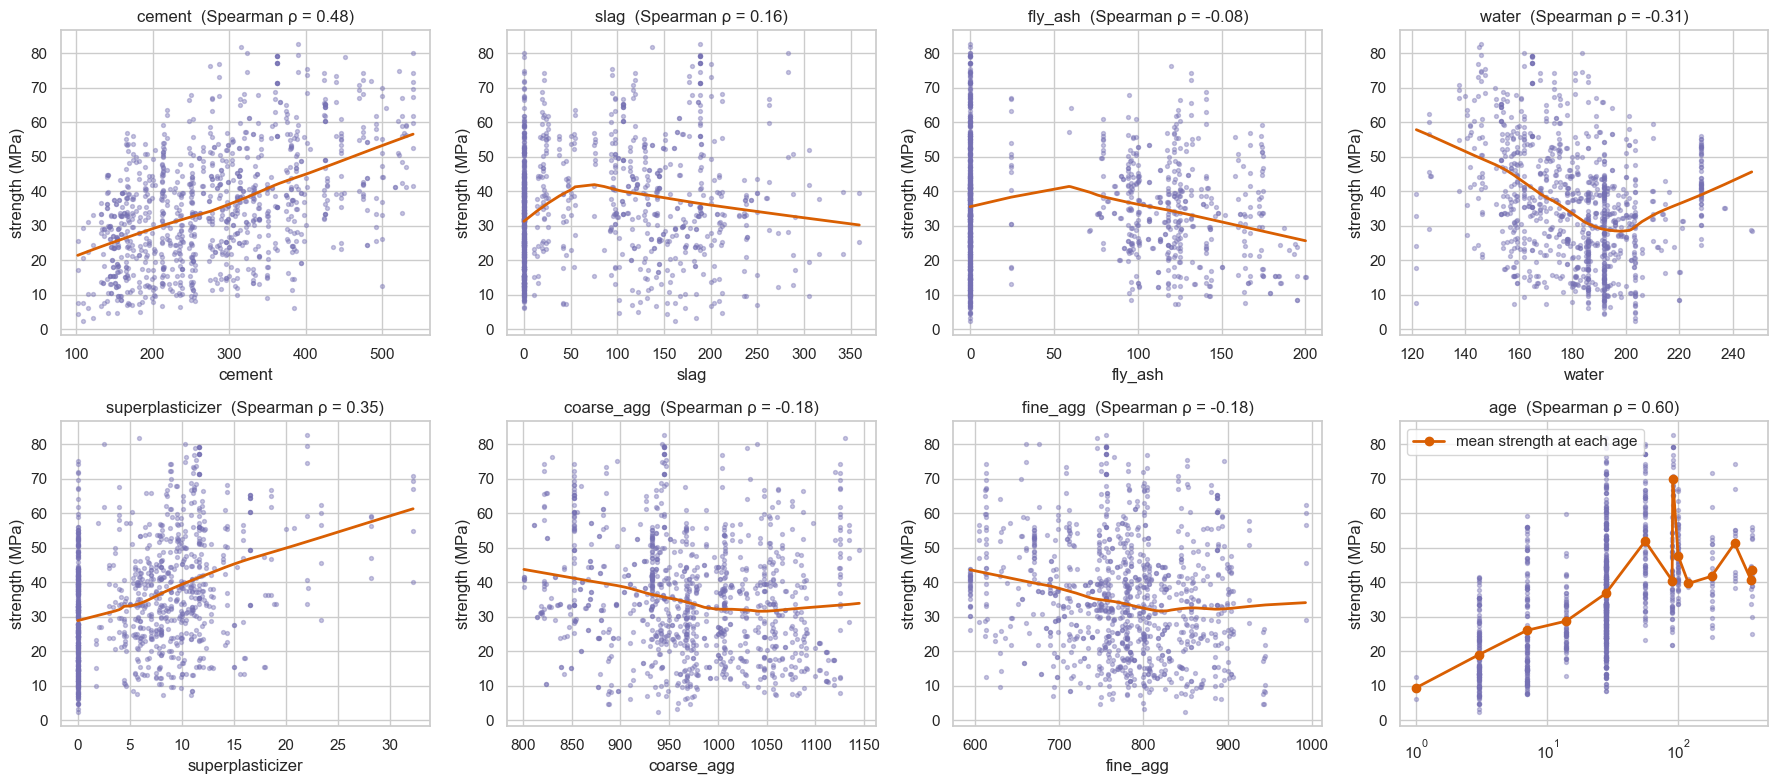

In [306]:

### Scatter plots of strength against each predictor
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), COMPONENTS + ["age"]):
    ax.scatter(concrete[c], concrete.strength, s=8, alpha=0.4, color="#7570b3")
    if c == "age":
        ax.set_xscale("log")
    else:
        sns.regplot(x=concrete[c], y=concrete.strength, scatter=False, lowess=True, ax=ax, color="#d95f02", line_kws={"lw": 2})
    ax.set_title(f"{c}  (Spearman ρ = {stats.spearmanr(concrete[c], concrete.strength)[0]:.2f})"); ax.set_ylabel("strength (MPa)")
age_means = concrete.groupby("age").strength.mean()
axes.ravel()[-1].plot(age_means.index, age_means.values, "o-", color="#d95f02", lw=2, label="mean strength at each age")
axes.ravel()[-1].legend()
plt.tight_layout()
plt.show()


 **Interpretation**
- **Age** has the strongest relationship with strength (ρ ≈ 0.60). It is clearly **non-linear (concave)**: mean strength rises steeply up to 28 days and then flattens. A straight line in raw age will not fit.
- **Cement** is the strongest *ingredient* (ρ ≈ 0.48), but the cloud is wide: at 300 kg/m³ strengths range from about 10 to 70 MPa. Cement alone explains only part of the variation.
- **Water** is negatively related (ρ ≈ −0.31) and **superplasticizer** positively (ρ ≈ 0.35), consistent with Abrams' law, since superplasticizer allows less water.
- Slag, fly ash and the aggregates show weak relationships on their own. Their effects probably depend on the other ingredients (**interactions**).


Covariance matrix (ingredients, kg/m³ squared):


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg
cement,"10,922.000","-2,481.000","-2,658.000",-182.000,58.000,-889.000,"-1,866.000"
slag,"-2,481.000","7,444.000","-1,787.000",198.000,22.000,"-1,905.000","-1,948.000"
fly_ash,"-2,658.000","-1,787.000","4,096.000",-351.000,144.000,-50.000,406.000
water,-182.000,198.000,-351.000,456.000,-84.000,-303.000,-772.000
superplasticizer,58.000,22.000,144.000,-84.000,36.000,-124.000,107.000
coarse_agg,-889.000,"-1,905.000",-50.000,-303.000,-124.000,"6,046.000","-1,113.000"
fine_agg,"-1,866.000","-1,948.000",406.000,-772.000,107.000,"-1,113.000","6,428.000"


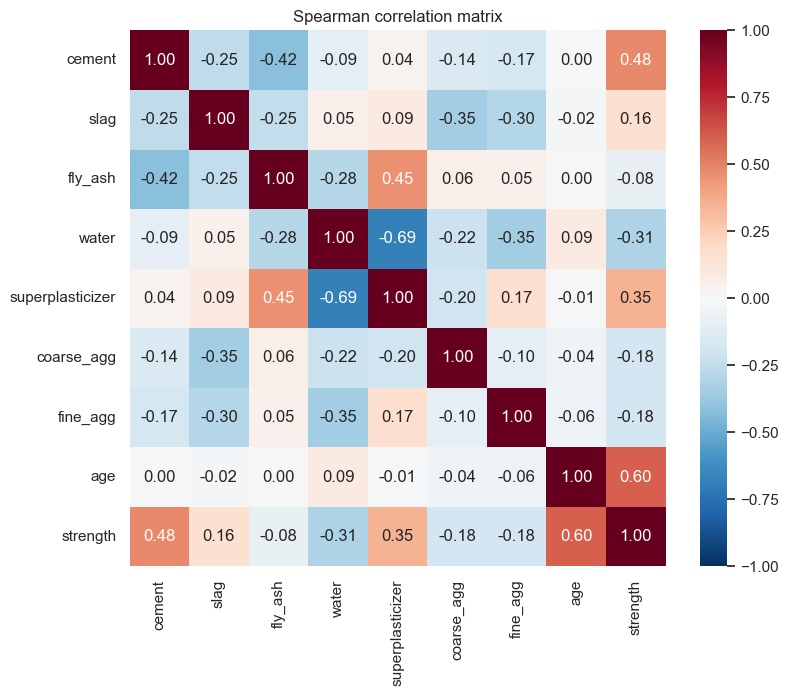

In [307]:

### Covariance and correlation among predictors
print("Covariance matrix (ingredients, kg/m³ squared):")
display(concrete[COMPONENTS].cov().round(0))
corr = concrete[COMPONENTS + ["age", "strength"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.show()


✍️ **Interpretation.** The covariance matrix is hard to read because the ingredients have different spreads, so we use the correlation matrix.
- `water` and `superplasticizer` are strongly **negatively** correlated (ρ ≈ −0.69). This is deliberate: superplasticizer is added *so that* less water is needed.
- **`cement` is negatively correlated with `fly_ash` (≈ −0.42) and `slag` (≈ −0.25).** These materials were used as **substitutes** for part of the cement. The ingredients were not varied independently, which is crucial for Question 3.
- No correlation is extreme, but the *Regression* showed that correlated predictors make least-squares coefficients unstable. We check this formally with variance inflation factors (VIF).



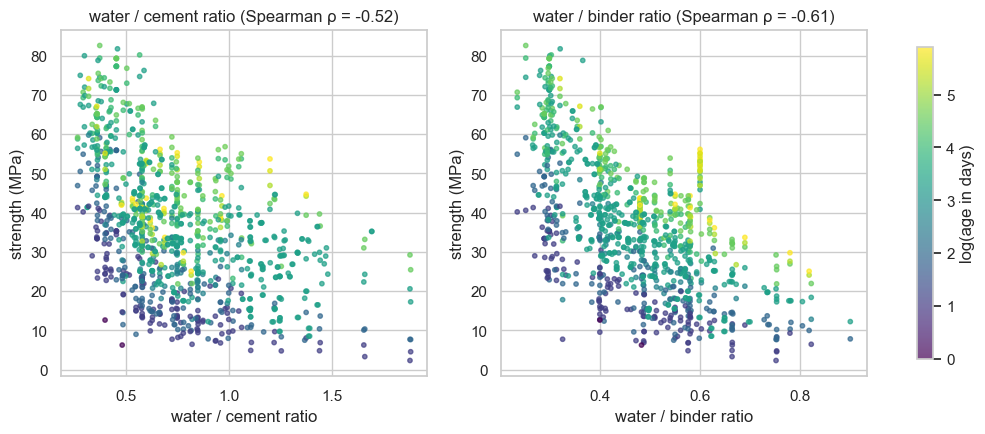

In [308]:

### Domain-motivated ratios: water/cement and water/binder
tmp = concrete.assign(w_c=concrete.water / concrete.cement, w_b=concrete.water / (concrete.cement + concrete.slag + concrete.fly_ash))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (c, label) in zip(axes, [("w_c", "water / cement ratio"), ("w_b", "water / binder ratio")]):
    sc = ax.scatter(tmp[c], tmp.strength, c=np.log(tmp.age), cmap="viridis", s=10, alpha=0.7)
    ax.set(xlabel=label, ylabel="strength (MPa)", title=f"{label} (Spearman ρ = {stats.spearmanr(tmp[c], tmp.strength)[0]:.2f})")
plt.colorbar(sc, ax=axes, shrink=0.9, label="log(age in days)")
plt.show()



**Interpretation.** 
-The **water/binder ratio** (binder = cement + slag + fly ash) is more strongly related to strength (ρ ≈ −0.61) than any single ingredient. 
-The colours show that, **at the same ratio, older specimens are stronger**. 
-Strength depends jointly on the ratio and on age, exactly as Abrams' law and curing theory predict. This justifies engineering these features .

In [309]:

##Data cleaning, transformation and reduction 

### Missing values
concrete.isnull().sum()


cement              0
slag                0
fly_ash             0
water               0
superplasticizer    0
coarse_agg          0
fine_agg            0
age                 0
strength            0
dtype: int64

**Interpretation and decision.** 
-There are **no missing values**. The many zeros are *real* values ("this ingredient was not used"). 
-Replacing them with the median, as the tutorial does for genuinely missing data, would invent ingredients that were never in the mix. 
-**No imputation is done.**



In [310]:
### Outliers: Z-scores and boxplots
Z = (concrete - concrete.mean()) / concrete.std()
print("Values with |Z| > 3, per attribute:")
print((Z.abs() > 3).sum().to_string())
flag = (Z.abs() > 3).any(axis=1)
print("\nRows with at least one |Z| > 3: %d (%.1f%%)" % (flag.sum(), 100 * flag.mean()))
concrete[flag].describe().loc[["mean", "min", "max"]]

Values with |Z| > 3, per attribute:
cement               0
slag                 4
fly_ash              0
water                2
superplasticizer    10
coarse_agg           0
fine_agg             0
age                 33
strength             0

Rows with at least one |Z| > 3: 49 (4.8%)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
mean,354.812,89.704,2.908,197.729,6.408,936.676,725.061,230.122,46.303
min,139.600,0.000,0.000,137.800,0.000,852.100,594.000,3.000,21.917
max,540.000,359.400,71.500,247.000,32.200,"1,125.000",893.700,365.000,74.167



 **Interpretation and decision**
- **49 rows (4.8%)** have some $|Z| > 3$. Most are **old specimens** (33 rows aged 180–365 days, the long tail of a skewed attribute). The rest are mixes with **high superplasticizer** (10), **high slag** (4) or **extreme water** content (2).
- These are **physically plausible lab results**, not recording errors: concrete *is* tested at 365 days, and high-performance mixes *do* use a lot of superplasticizer. Removing them would delete exactly the conditions where the model most needs data.
- **Decision: keep them.** We reduce their influence by using **log(age)** in the linear models, and we check whether any single observation has an undue effect on the fitted model with *influence diagnostics* in Step 7.5. That is the regression version of outlier detection from the Lecture 2 flowchart.


In [311]:

### Duplicate data
print("Number of duplicate rows = %d" % concrete.duplicated().sum())
print("Number of rows before discarding duplicates = %d" % concrete.shape[0])
df = concrete.drop_duplicates().reset_index(drop=True)
print("Number of rows after discarding duplicates = %d" % df.shape[0])

Number of duplicate rows = 25
Number of rows before discarding duplicates = 1030
Number of rows after discarding duplicates = 1005


 **Interpretation and decision.**
 - There are **25 exact duplicates**: the same mix, the same age *and* the same strength to two decimals. 
 -  A genuine repeat test would almost never give an identical strength, so these are repeated records. We **remove** them. 
 -  A duplicate in both training and test sets would let the model "recognise" a test row and look better than it is.

In [312]:

### Discretisation of age: equal-width vs equal-depth bins
print("Distinct ages and their counts:", df.age.value_counts().sort_index().to_dict(), "\n")
print("Equal-WIDTH bins (pd.cut):\n", df.groupby(pd.cut(df.age, 5), observed=True).strength.agg(["count", "mean"]).round(1), "\n")
print("Equal-DEPTH bins (pd.qcut):\n", df.groupby(pd.qcut(df.age, 4, duplicates="drop"), observed=True).strength.agg(["count", "mean"]).round(1))

Distinct ages and their counts: {1: 2, 3: 129, 7: 122, 14: 62, 28: 419, 56: 86, 90: 54, 91: 17, 100: 52, 120: 3, 180: 26, 270: 13, 360: 6, 365: 14} 

Equal-WIDTH bins (pd.cut):
                 count   mean
age                         
(0.636, 73.8]     820 32.800
(73.8, 146.6]     126 47.200
(146.6, 219.4]     26 41.700
(219.4, 292.2]     13 51.300
(292.2, 365.0]     20 42.700 

Equal-DEPTH bins (pd.qcut):
                count   mean
age                        
(0.999, 7.0]     253 21.600
(7.0, 28.0]      481 35.400
(28.0, 56.0]      86 50.700
(56.0, 365.0]    185 46.300


**Interpretation and decision.**
- Age takes only **14 distinct values**, and **28 days**, the industry-standard test age, accounts for about 41% of rows.
- **Equal-width bins** put almost everything into the first bin (1–73.8 days), because of the skew. They hide the early-age changes where strength moves fastest.
- **Equal-depth bins** spread the rows more evenly and show the concave pattern: mean strength rises from ≈22 MPa (≤7 days) to ≈35 MPa (7–28 days) and ≈46–51 MPa (over 28 days).
- **Decision:** keep age **numeric**, but use **log(age)** for linear models. A log transform spreads out the early ages just as equal-depth bins do, without throwing information away. For residual analysis (Step 10) we use bins that follow the testing schedule.



In [313]:
## Aggregation: the same mix is tested at several ages
##We group the rows by their 7-ingredient **recipe** to see how many distinct mixes there are.
df["mix_id"] = df.groupby(COMPONENTS).ngroup()
per_mix = df.groupby("mix_id").agg(n_tests=("age", "size"), n_ages=("age", "nunique"))
print(f"Distinct mixture designs: {df.mix_id.nunique()} across {len(df)} rows")
print("Number of rows per mix:", per_mix.n_tests.value_counts().sort_index().to_dict())
example = per_mix.n_tests.idxmax()
df[df.mix_id == example].sort_values("age")[["cement", "water", "age", "strength"]]

Distinct mixture designs: 428 across 1005 rows
Number of rows per mix: {1: 246, 2: 42, 3: 7, 4: 38, 5: 77, 6: 12, 7: 3, 8: 3}


,cement,water,age,strength
501,359.000,154.000,3,25.117
502,359.000,154.000,3,23.639
503,359.000,154.000,7,35.754
504,359.000,154.000,7,38.611
499,359.000,154.000,28,62.935
500,359.000,154.000,28,59.495
505,359.000,154.000,56,68.751
506,359.000,154.000,56,66.781


**Interpretation: a hidden structure that changes how we must validate.** 
-The 1,005 rows contain only **428 distinct mixes**; 182 of them were tested more than once. 
-The example mix was crushed twice at each of 4 ages (3, 7, 28 and 56 days), with strength rising from ≈24 to ≈68 MPa. The two tests at the same age differ by a few MPa, which shows the size of genuine **replicate variation**.
- It also confirms that the 25 rows with *identical* strengths removed  were duplicated records, not real repeat tests. Rows of the same mix are **not independent**.

If we split rows at random, the same mix would appear in training (say at 28 days) and in testing (at 56 days). The model would only need to *interpolate along a curing curve it already knows*, which is much easier than predicting a **new** mix design, the real use case. **Decision:** all splits and cross-validation are done **by mix** so test mixes are always completely unseen.


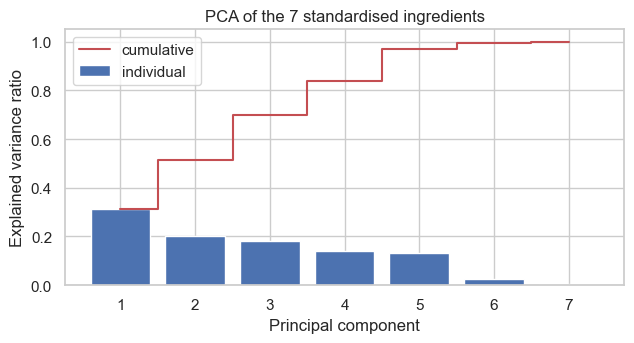

Explained variance: [0.314 0.202 0.182 0.14  0.132 0.027 0.004]
Cumulative: [0.314 0.516 0.697 0.837 0.969 0.996 1.   ]

Total mass of all ingredients per m³: mean 2341 kg, sd 65 kg


In [314]:

###  Dimensionality reduction: PCA of the ingredients
pca_ing = PCA().fit(StandardScaler().fit_transform(df[COMPONENTS]))
ratio = pca_ing.explained_variance_ratio_
plt.figure(figsize=(6.5, 3.6))
plt.bar(range(1, 8), ratio, label="individual"); plt.step(range(1, 8), np.cumsum(ratio), where="mid", color="r", label="cumulative")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio"); plt.title("PCA of the 7 standardised ingredients"); plt.legend()
plt.tight_layout()
plt.show()
print("Explained variance:", np.round(ratio, 3))
print("Cumulative:", np.round(np.cumsum(ratio), 3))
total = df[COMPONENTS].sum(axis=1)
print(f"\nTotal mass of all ingredients per m³: mean {total.mean():.0f} kg, sd {total.std():.0f} kg")


**Interpretation.**
- Unlike the macro-economic data in Project 1, the ingredient variance is **spread across many components**: the first 3 explain only ≈70% and 5 are needed for ≈97%. Only the last two components are nearly empty (≈2.7% and ≈0.4%), and the last one is the **mixture constraint**: the ingredients add up to ≈2,340 kg/m³, the weight of a cubic metre of concrete, with a small spread (sd ≈ 65 kg). 
-   Concrete data are therefore **compositional**: adding one ingredient means removing something else. This matters for Question 3. It also suggests that PCA will not compress these inputs much without losing information.


In [315]:

### Feature engineering (transformation)
def add_engineered(X: pd.DataFrame) -> pd.DataFrame:
    """Row-wise domain features (nothing is learned from the data → no leakage)."""
    X = X.copy()
    binder = X["cement"] + X["slag"] + X["fly_ash"]
    X["log_age"] = np.log(X["age"])
    X["w_c"] = X["water"] / X["cement"]
    X["w_b"] = X["water"] / binder
    X["scm_frac"] = (X["slag"] + X["fly_ash"]) / binder
    X["sp_used"] = (X["superplasticizer"] > 0).astype(int)
    return X

RAW_FEATURES = COMPONENTS + ["age"]
add_engineered(df[RAW_FEATURES]).head()

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,log_age,w_c,w_b,scm_frac,sp_used
0,540.000,0.000,0.000,162.000,2.500,"1,040.000",676.000,28,3.332,0.300,0.300,0.000,1
1,540.000,0.000,0.000,162.000,2.500,"1,055.000",676.000,28,3.332,0.300,0.300,0.000,1
2,332.500,142.500,0.000,228.000,0.000,932.000,594.000,270,5.598,0.686,0.480,0.300,0
3,332.500,142.500,0.000,228.000,0.000,932.000,594.000,365,5.900,0.686,0.480,0.300,0
4,198.600,132.400,0.000,192.000,0.000,978.400,825.500,360,5.886,0.967,0.580,0.400,0


In [316]:

### Sampling: a group-aware train/test split
X_all, y_all, groups_all = df[RAW_FEATURES], df["strength"], df["mix_id"]
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED).split(X_all, y_all, groups_all))
X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
g_train, g_test = groups_all.iloc[train_idx], groups_all.iloc[test_idx]
assert set(g_train).isdisjoint(set(g_test)), "a mix appears in both train and test!"
print(f"Training set: {len(X_train)} rows from {g_train.nunique()} mixes | Test set: {len(X_test)} rows from {g_test.nunique()} mixes")
print(f"Mean strength — training {y_train.mean():.2f} MPa, test {y_test.mean():.2f} MPa")


Training set: 810 rows from 342 mixes | Test set: 195 rows from 86 mixes
Mean strength — training 35.30 MPa, test 35.03 MPa


### Short data report

| Aspect | Finding | Decision / implication |
|---|---|---|
| Size & type | 1,030 rows; 8 quantitative predictors (7 ingredients kg/m³ + age in days); continuous response (MPa) | Multiple, univariate regression; a small dataset → careful validation |
| Response | 2.3–82.6 MPa, mean 35.8, sd 16.7, nearly symmetric | No transformation; mean baseline RMSE ≈ 16 MPa |
| Missing / zeros | No missing values; many **structural zeros** (slag 45%, fly ash 55%, superplasticizer 37%) | No imputation |
| Outliers | ≈5% of rows have some \|Z\| > 3, but they are plausible | Kept; log(age); influence diagnostics  |
| Duplicates | 25 exact duplicates | Removed → 1,005 rows |
| Repeated mixes | Only 428 distinct mixes, many tested at several ages | **Group-aware** split and cross-validation |
| Age | 14 discrete values, strongly skewed, 41% at 28 days | log(age) for linear models; expect weaker predictions at rare ages |
| Non-linearity | Concave age effect; ratio (Abrams) effect; interactions | Compare linear, engineered-linear and non-linear models |
| Correlation / design | Cement substitutes (slag, fly ash) negatively correlated; water ↔ superplasticizer | Coefficients are not "all else equal" effects (relevant to Question 3) |
| Compositional | Ingredients sum to ≈2,340 ± 65 kg/m³ | Cannot change one ingredient alone |

**Limitations of the data.** The data were compiled from several laboratories and important factors were not recorded: cement type and grade, aggregate type, curing temperature and humidity, specimen size. These add noise that no model can remove, and they may **confound** the relationships we see.


## Goodness-of-fit measures, validation design and the mean baseline

In [317]:


###  Mean-prediction baseline
## The baseline predicts the **training mean** for every mix. Every model must beat it.
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def regression_report(y_true, y_pred, p=None):
    res = np.asarray(y_true) - np.asarray(y_pred)
    out = {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred),
           "R2": r2_score(y_true, y_pred)}
    if p is not None:
        out["adj. R2"] = adjusted_r2(out["R2"], len(res), p)
    out.update({"bias (mean residual)": res.mean(), "over-estimated by >5 MPa (%)": 100 * np.mean(res < -5)})
    return out

SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def grouped_cv(model, X=X_train, y=y_train, groups=g_train, seeds=(0, 1, 2), n_splits=5):
    """Repeated, shuffled GroupKFold: no mix is ever in both the fitting and the validation folds."""
    out = {"rmse": [], "mae": [], "r2": []}
    for s in seeds:
        r = cross_validate(model, X, y, groups=groups, cv=GroupKFold(n_splits=n_splits, shuffle=True, random_state=s), scoring=SCORING)
        out["rmse"] += list(-r["test_rmse"]); out["mae"] += list(-r["test_mae"]); out["r2"] += list(r["test_r2"])
    return {k: np.array(v) for k, v in out.items()}

baseline = DummyRegressor(strategy="mean")
cv_store = {"Mean baseline": grouped_cv(baseline)}
baseline.fit(X_train, y_train)
print(f"Baseline prediction (training mean): {baseline.constant_[0][0]:.2f} MPa")
cvb, tb = cv_store["Mean baseline"], regression_report(y_test, baseline.predict(X_test))
pd.DataFrame({"grouped CV (mean ± sd)": {m.upper() if m != "r2" else "R2": f"{v.mean():.3f} ± {v.std():.3f}" for m, v in cvb.items()},
              "test set": {k: f"{tb[k]:.3f}" for k in ["RMSE", "MAE", "R2"]}})

Baseline prediction (training mean): 35.30 MPa


,grouped CV (mean ± sd),test set
RMSE,16.292 ± 0.962,16.158
MAE,13.216 ± 0.939,12.921
R2,-0.011 ± 0.017,-0.000


**Interpretation.** 
-Predicting the training mean (35.3 MPa) for every mix gives **RMSE ≈ 16.2–16.3 MPa** (about the standard deviation of strength), **MAE ≈ 13 MPa** and **R² ≈ 0**. 
-These are the numbers to beat. A slightly negative R² is normal when a mean from one set of rows is applied to another.


## Formulating the candidate models (linear vs non-linear)

Following the lecture's definition (*linear* = parameters enter linearly), we compare:

| ID | Model | Linear in parameters? | Fitting method | Purpose |
|---|---|---|---|---|
| **L1** | Multiple linear regression on the 8 raw predictors | ✅ Linear | **Least squares** | The naive linear benchmark |
| **L2** | Multiple linear regression on raw + engineered features | ✅ Linear | **Least squares** | How far does domain knowledge take a linear model? |
| L2-R / L2-L / L2-P | L2's features fitted by **ridge**, **lasso** and **principal-components regression** | ✅ Linear | Ridge, lasso, PCR (CV-tuned) | Does a different fitting method help with correlated predictors? |
| **L3** | Ridge regression on all squares and pairwise products of the inputs (degree-2 polynomial) | ✅ Linear (still linear in β!) | Ridge | A flexible linear model that can bend and interact |
| **N1** | **Abrams-type strength model**: $\hat{y} = A\,e^{-k\,w/b_{\text{eff}}}\cdot \frac{t^{n}}{t_{50}^{n} + t^{n}} + \beta_{sp}\,SP$ | ❌ **Non-linear** | **Non-linear least squares** | A physically meaningful, non-linear-in-parameters model with only 7 parameters |
| **N2** | Random forest | ❌ Non-linear (non-parametric) | Bagged regression trees | Learns non-linearities and interactions automatically |
| **N3** | Gradient-boosted trees | ❌ Non-linear (non-parametric) | Boosted regression trees | Usually the most accurate learner on tabular data |

*About maximum likelihood (MLE), the fourth fitting method in the lecture.* If the errors are independent and normally distributed, the least-squares estimates **are** the maximum-likelihood estimates. L1 and L2 are therefore also MLE fits under that assumption.

In [318]:

## Fitting and validating the linear models
###Fit L1: least squares on the raw predictors
ols1 = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols1.summary().tables[1])
print(f"\nR² = {ols1.rsquared:.3f}, adjusted R² = {ols1.rsquared_adj:.3f}, n = {int(ols1.nobs)}, p = {int(ols1.df_model)}")

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -24.0327     29.574     -0.813      0.417     -82.085      34.020
cement               0.1169      0.010     12.162      0.000       0.098       0.136
slag                 0.0959      0.011      8.522      0.000       0.074       0.118
fly_ash              0.0818      0.014      5.714      0.000       0.054       0.110
water               -0.1366      0.045     -3.040      0.002      -0.225      -0.048
superplasticizer     0.3844      0.109      3.541      0.000       0.171       0.597
coarse_agg           0.0158      0.010      1.521      0.129      -0.005       0.036
fine_agg             0.0223      0.012      1.847      0.065      -0.001       0.046
age                  0.1140      0.006     18.797      0.000       0.102       0.126

R² = 0.592, adjusted R² = 0.588, n = 810, p = 8


**Interpretation of the coefficients.** 
-Holding the other inputs fixed, each extra kg/m³ of **cement** adds ≈0.12 MPa, **slag** ≈0.10 and **fly ash** ≈0.08. Each kg of **water** subtracts ≈0.14 MPa, and each day of **age** adds ≈0.11 MPa. 
-The signs agree with concrete science. But R² is only ≈0.59. Before trusting these numbers we must **validate the assumptions**.

### Validate assumptions for L1: residual plots and formal tests
| Assumption of least squares | How we check it |
|---|---|
| The mean of *y* is linear in the predictors | Residuals vs fitted values (should be a shapeless band around 0); **Ramsey RESET test** |
| Constant error variance (homoscedasticity) | Spread of residuals vs fitted; **Breusch–Pagan test** |
| Errors roughly normal (needed for p-values and for OLS = MLE) | **Normal Q–Q plot**; Shapiro–Wilk test |
| No severe multicollinearity | **Variance inflation factor (VIF)**; values above ≈10 are a warning |

Ramsey RESET (linearity):          F = 57.2, p = 1.1e-13
Breusch–Pagan (constant variance): LM = 101.1, p = 2.6e-18
Shapiro–Wilk (normality):          W = 0.996, p = 0.052
Variance inflation factors: {'cement': 7.1, 'slag': 7.3, 'fly_ash': 6.2, 'water': 6.6, 'superplasticizer': 3.0, 'coarse_agg': 4.7, 'fine_agg': 6.8, 'age': 1.1}


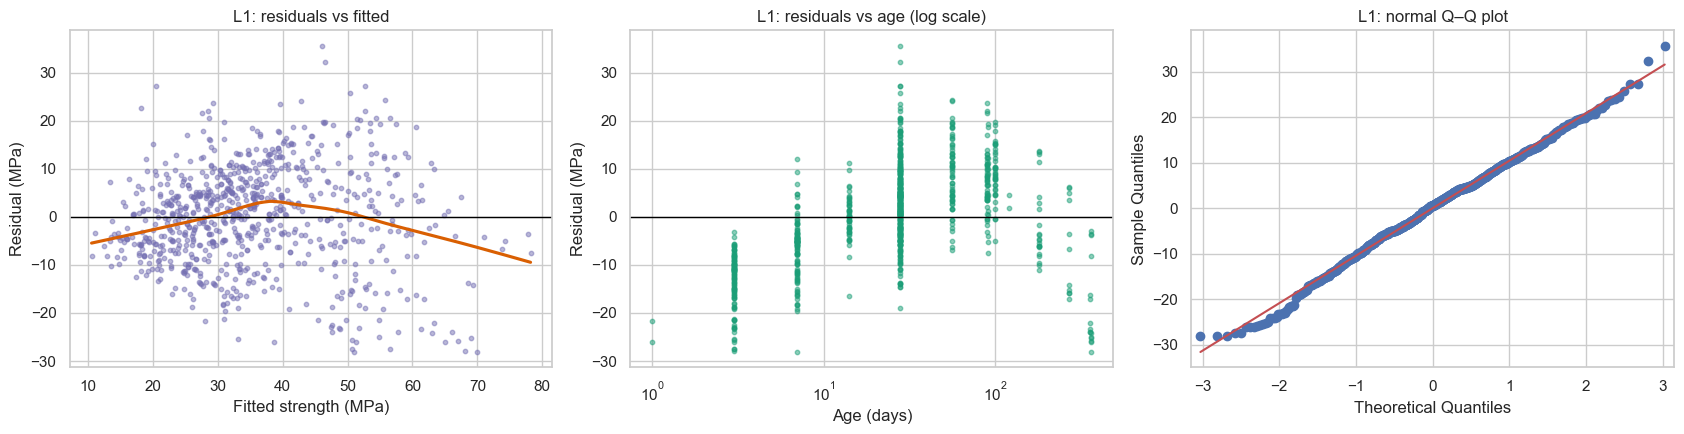

In [319]:

X1c = sm.add_constant(X_train)
bp = het_breuschpagan(ols1.resid, X1c)
sw = stats.shapiro(ols1.resid)
reset = sm.stats.diagnostic.linear_reset(ols1, power=2, use_f=True)
vif = pd.Series([variance_inflation_factor(X1c.values, i) for i in range(1, X1c.shape[1])], index=X_train.columns)
print(f"Ramsey RESET (linearity):          F = {reset.fvalue:.1f}, p = {reset.pvalue:.1e}")
print(f"Breusch–Pagan (constant variance): LM = {bp[0]:.1f}, p = {bp[1]:.1e}")
print(f"Shapiro–Wilk (normality):          W = {sw[0]:.3f}, p = {sw[1]:.3f}")
print("Variance inflation factors:", vif.round(1).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(ols1.fittedvalues, ols1.resid, s=10, alpha=0.5, color="#7570b3")
sns.regplot(x=ols1.fittedvalues, y=ols1.resid, scatter=False, lowess=True, ax=axes[0], color="#d95f02")
axes[0].axhline(0, color="black", lw=1); axes[0].set(title="L1: residuals vs fitted", xlabel="Fitted strength (MPa)", ylabel="Residual (MPa)")
axes[1].scatter(X_train["age"], ols1.resid, s=10, alpha=0.5, color="#1b9e77"); axes[1].set_xscale("log")
axes[1].axhline(0, color="black", lw=1); axes[1].set(title="L1: residuals vs age (log scale)", xlabel="Age (days)", ylabel="Residual (MPa)")
sm.qqplot(ols1.resid, line="s", ax=axes[2]); axes[2].set_title("L1: normal Q–Q plot")
plt.tight_layout()
plt.show()


**Validation of L1 — the assumptions are NOT OK**

| Assumption | Evidence | Verdict |
|---|---|---|
| Linear mean function | RESET F = 57, p ≈ 10⁻¹³. The LOWESS line in *residuals vs fitted* is curved, and *residuals vs age* is clearly curved: under-estimated at middle ages, over-estimated at 180–365 days | **Violated.** Raw age enters as a straight line but strength gain is concave |
| Constant variance | Breusch–Pagan LM = 101, p ≈ 10⁻¹⁸. The residual spread widens as fitted strength rises | **Violated.** Standard errors and p-values are unreliable |
| Normal errors | Shapiro–Wilk p = 0.052; the Q–Q plot is close to the line | Approximately OK |
| Multicollinearity | All VIF < 7.5 (slag 7.3, cement 7.1) | Moderate, as expected from the substitution between ingredients, but not severe |

**Decision (flowchart arrow "No").** The model form is wrong, so we go back to *Formulate the problem*.


### Back to "Formulate": L2, the domain-engineered linear model
The flowchart says that when the assumptions are **not OK**, we go back and **re-formulate** the model. The diagnostics point to two fixes: use **log(age)**, and add the **water/cement and water/binder ratios** (Abrams' law). We refit and re-validate.

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -54.8979     19.724     -2.783      0.006     -93.615     -16.181
cement               0.1063      0.013      8.197      0.000       0.081       0.132
slag                 0.0520      0.015      3.559      0.000       0.023       0.081
fly_ash              0.0069      0.017      0.408      0.683      -0.026       0.040
water               -0.0703      0.037     -1.880      0.060      -0.144       0.003
superplasticizer    -0.1955      0.087     -2.250      0.025      -0.366      -0.025
coarse_agg           0.0192      0.007      2.826      0.005       0.006       0.033
fine_agg             0.0287      0.008      3.581      0.000       0.013       0.044
age                 -0.0317      0.006     -5.067      0.000      -0.044      -0.019
log_age              9.9050      0.322     30.732      0.000     

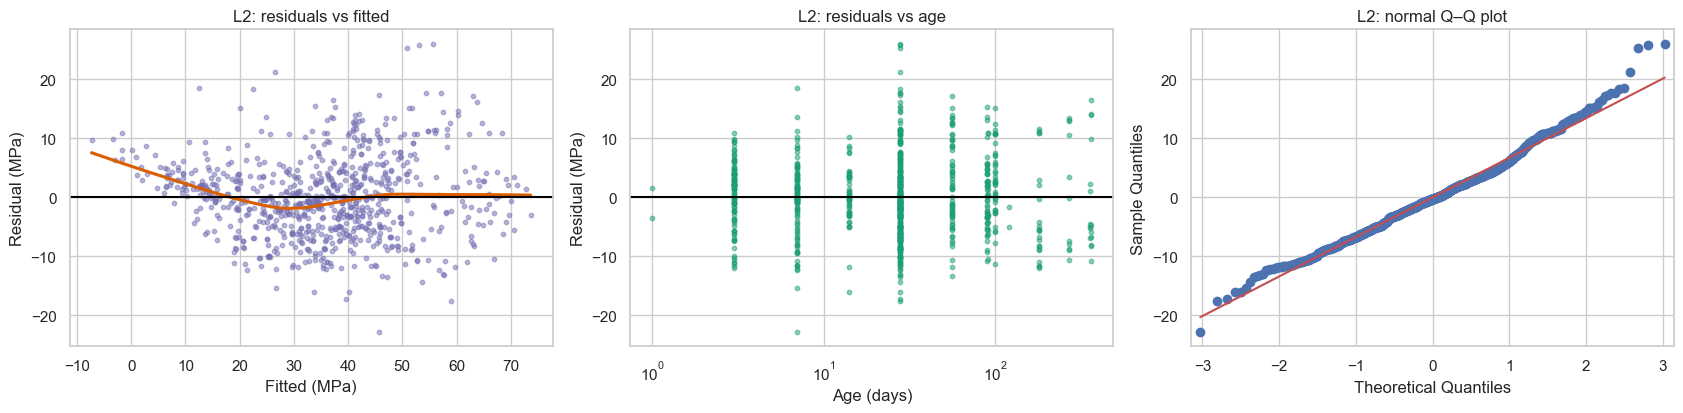

In [320]:

Xe_train = add_engineered(X_train)
ols2 = sm.OLS(y_train, sm.add_constant(Xe_train)).fit()
reset2 = sm.stats.diagnostic.linear_reset(ols2, power=2, use_f=True)
bp2 = het_breuschpagan(ols2.resid, sm.add_constant(Xe_train))
sw2 = stats.shapiro(ols2.resid)
print(ols2.summary().tables[1])
print(f"\nR² = {ols2.rsquared:.3f} (L1: {ols1.rsquared:.3f}); adjusted R² = {ols2.rsquared_adj:.3f} (L1: {ols1.rsquared_adj:.3f})")
print(f"RESET p = {reset2.pvalue:.1e} | Breusch–Pagan p = {bp2[1]:.1e} | Shapiro–Wilk p = {sw2[1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].scatter(ols2.fittedvalues, ols2.resid, s=10, alpha=0.5, color="#7570b3")
sns.regplot(x=ols2.fittedvalues, y=ols2.resid, scatter=False, lowess=True, ax=axes[0], color="#d95f02")
axes[0].axhline(0, color="black"); axes[0].set(title="L2: residuals vs fitted", xlabel="Fitted (MPa)", ylabel="Residual (MPa)")
axes[1].scatter(X_train["age"], ols2.resid, s=10, alpha=0.5, color="#1b9e77"); axes[1].set_xscale("log")
axes[1].axhline(0, color="black"); axes[1].set(title="L2: residuals vs age", xlabel="Age (days)", ylabel="Residual (MPa)")
sm.qqplot(ols2.resid, line="s", ax=axes[2]); axes[2].set_title("L2: normal Q–Q plot")
plt.tight_layout()
plt.show()


**Interpretation of the re-formulated model**
- **Much better fit.** R² rises from 0.59 to **0.83** (adjusted R² 0.588 → **0.828**, so the gain is not just from adding predictors). `log_age` is by far the strongest term (t ≈ 31): each doubling of age adds about 9.9 × ln 2 ≈ 6.9 MPa. The water/cement ratio has the expected negative sign.
- **Better, but still not perfect.** The age curvature has largely gone from *residuals vs age*. However, RESET (p ≈ 10⁻⁹) and Breusch–Pagan (p ≈ 10⁻⁸) are still significant. The *residuals vs fitted* plot still bends at low fitted values: the model predicts *negative* strengths for some weak early-age mixes, which is physically impossible. The Q–Q plot shows a heavier upper tail, a few strong mixes that the model under-estimates. **Some non-linearity and interaction remains that a linear model cannot capture.** This motivates the non-linear models.
- **Caution about individual coefficients.** Some signs look odd. `superplasticizer` is negative while `sp_used` is +7.1. Raw `age` is negative while `log_age` is positive. `w_b` is not significant. These terms are **correlated with each other** (for example, `age` with `log_age`, and `w_c` with `w_b` and `cement`), so the coefficients share the work and cannot be read one at a time. This is the *Regression* tutorial's lesson on correlated attributes. -The model is built for **prediction**, not for interpreting single coefficients.

In [321]:

### Comparing fitting methods on L2's features: least squares, ridge, lasso, PCR
eng = FunctionTransformer(add_engineered)
fit_methods = {
    "Least squares (L2)": Pipeline([("eng", eng), ("sc", StandardScaler()), ("m", LinearRegression())]),
    "Ridge (α by CV)": Pipeline([("eng", eng), ("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(-3, 3, 30)))]),
    "Lasso (α by CV)": Pipeline([("eng", eng), ("sc", StandardScaler()), ("m", LassoCV(cv=5, random_state=SEED, max_iter=50000))]),
}
pcr_search = GridSearchCV(Pipeline([("eng", eng), ("sc", StandardScaler()), ("pca", PCA()), ("m", LinearRegression())]),
                          {"pca__n_components": list(range(1, 14))}, scoring="neg_root_mean_squared_error",
                          cv=GroupKFold(5, shuffle=True, random_state=SEED))
pcr_search.fit(X_train, y_train, groups=g_train)
fit_methods["PCR (k by CV)"] = pcr_search.best_estimator_

rows = {}
for name, m in fit_methods.items():
    cvr = grouped_cv(clone(m)); fitted_m = clone(m).fit(X_train, y_train)
    w = fitted_m.named_steps["m"].coef_
    if "pca" in fitted_m.named_steps:
        w = fitted_m.named_steps["pca"].components_.T @ w      # back to the standardised original features
    extra = ""
    if hasattr(fitted_m.named_steps["m"], "alpha_"): extra = f"α = {fitted_m.named_steps['m'].alpha_:.4g}"
    if "pca" in fitted_m.named_steps: extra = f"k = {fitted_m.named_steps['pca'].n_components_} components"
    rows[name] = {"setting chosen": extra, "training RMSE": np.sqrt(mean_squared_error(y_train, fitted_m.predict(X_train))),
                  "grouped-CV RMSE": cvr["rmse"].mean(), "CV RMSE sd": cvr["rmse"].std(), "CV R²": cvr["r2"].mean(),
                  "sum of |weights|": np.abs(w).sum(), "weights set to 0": int(np.sum(np.abs(w) < 1e-8))}
fit_tbl = pd.DataFrame(rows).T
fit_tbl

,setting chosen,training RMSE,grouped-CV RMSE,CV RMSE sd,CV R²,sum of |weights|,weights set to 0
Least squares (L2),,6.703,7.021,0.371,0.810,47.725,0
Ridge (α by CV),α = 1.269,6.704,7.022,0.370,0.810,45.937,0
Lasso (α by CV),α = 0.2235,6.888,7.252,0.492,0.798,30.487,3
PCR (k by CV),k = 13 components,6.703,7.021,0.371,0.810,47.725,0


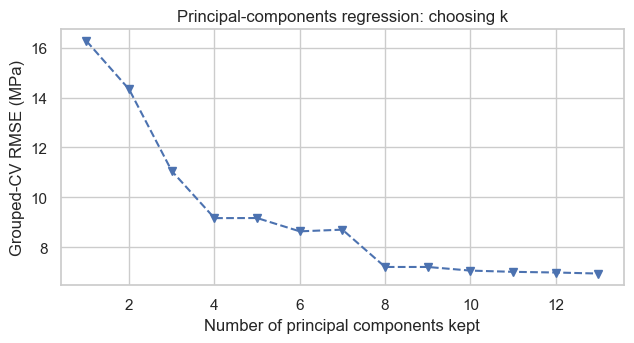

In [322]:
##pcr curve
pcr_curve = pd.DataFrame(pcr_search.cv_results_)[["param_pca__n_components", "mean_test_score"]]
plt.figure(figsize=(6.5, 3.6))
plt.plot(pcr_curve.param_pca__n_components, -pcr_curve.mean_test_score, "bv--")
plt.xlabel("Number of principal components kept"); plt.ylabel("Grouped-CV RMSE (MPa)"); plt.title("Principal-components regression: choosing k")
plt.tight_layout()
plt.show()


**Interpretation: does the fitting method matter?**
- **Ridge** chose a small penalty (α ≈ 1.3). It shrinks the sum of absolute weights slightly (47.7 → 45.9) with **identical** accuracy (CV RMSE 7.02). Collinearity is not damaging *prediction* here.
- **Lasso** (α ≈ 0.22) set **3 coefficients exactly to zero**, making a sparser model (sum of |weights| 30.5), as the *Regression* tutorial §5.5 describes. Here the sparsity **costs** a little accuracy (7.25 vs 7.02 MPa): all the features carry some useful signal.
- **Principal-components regression.** Cross-validation chose **all 13 components** (the error keeps falling as *k* grows, see the plot), which makes PCR identical to least squares. No small set of components captures what matters for strength. This is consistent with Step 4.6, where the ingredient variance was spread over many components.
- **Maximum likelihood.** Under normal errors, least squares *is* the MLE. The Q–Q plot shows near-normal residuals apart from the upper tail, so this equivalence roughly holds.
- **Conclusion.** The limitation of the linear model is its **form** (it cannot bend or interact enough), not the **fitting method**. Changing the fitting method cannot fix a mis-specified form.


### Outlier detection for the regression: leverage, studentised residuals and Cook's distance
The flowchart lists **outlier detection** under "Validate assumptions". In regression, a point can be unusual in two ways (Chatterjee & Hadi, Ch. 4):
- **Outlying in y:** a large **studentised residual**. Rule of thumb: |r| > 3.
- **Outlying in X (high leverage):** an unusual combination of predictors. Leverage $h_{ii} > 2p/n$.
- **Influential:** removing the point changes the fitted model a lot. **Cook's distance** $D_i > 4/n$.

Studentised residuals with |r| > 3: 5
High-leverage points (h > 2p/n = 0.035): 65
Influential points (Cook's D > 4/n = 0.0049): 57; largest Cook's D = 0.025


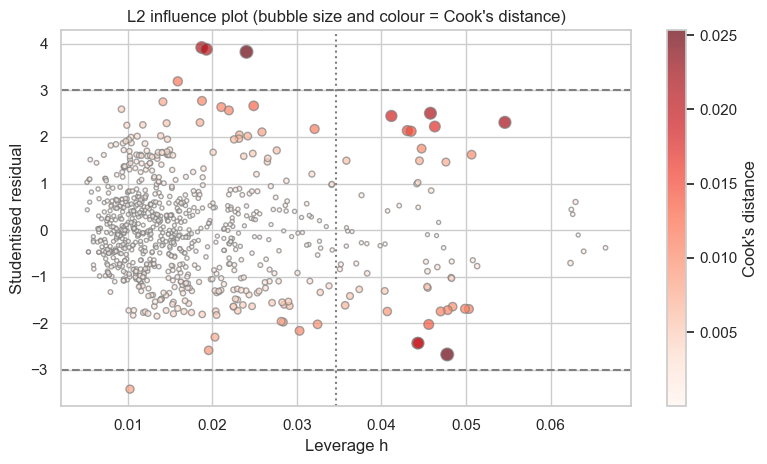

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,cooks_d,stud_resid
380,275.000,180.000,120.000,162.000,10.350,830.000,765.000,28,76.235,0.025,3.827
372,516.000,0.000,0.000,162.000,8.260,801.000,802.000,28,41.369,0.025,-2.667
837,140.000,164.000,128.000,237.000,6.000,869.000,656.000,28,35.225,0.022,2.314
34,190.000,190.000,0.000,228.000,0.000,932.000,670.000,365,53.692,0.021,2.510
359,451.000,0.000,0.000,165.000,11.250,"1,030.000",745.000,28,78.800,0.021,3.882
357,315.000,137.000,0.000,145.000,5.900,"1,130.000",745.000,28,81.751,0.021,3.920


In [323]:

infl = ols2.get_influence()
stud = infl.resid_studentized_external; lev = infl.hat_matrix_diag; cook = infl.cooks_distance[0]
n, p = int(ols2.nobs), int(ols2.df_model) + 1
print(f"Studentised residuals with |r| > 3: {np.sum(np.abs(stud) > 3)}")
print(f"High-leverage points (h > 2p/n = {2 * p / n:.3f}): {np.sum(lev > 2 * p / n)}")
print(f"Influential points (Cook's D > 4/n = {4 / n:.4f}): {np.sum(cook > 4 / n)}; largest Cook's D = {cook.max():.3f}")

fig, ax = plt.subplots(figsize=(8, 4.8))
sc = ax.scatter(lev, stud, s=8 + 3000 * cook, c=cook, cmap="Reds", alpha=0.7, edgecolor="grey")
ax.axhline(3, ls="--", color="grey"); ax.axhline(-3, ls="--", color="grey"); ax.axvline(2 * p / n, ls=":", color="grey")
ax.set(xlabel="Leverage h", ylabel="Studentised residual", title="L2 influence plot (bubble size and colour = Cook's distance)")
plt.colorbar(sc, label="Cook's distance"); plt.tight_layout(); plt.savefig(FIG_DIR / "p2_influence.png"); plt.show()

top_infl = Xe_train.assign(strength=y_train, cooks_d=cook, stud_resid=stud).sort_values("cooks_d", ascending=False)
top_infl[RAW_FEATURES + ["strength", "cooks_d", "stud_resid"]].head(6)

In [324]:
## Sensitivity analysis: refit L2 without the influential points
## The last box under "Validate assumptions" is **sensitivity analysis**: *do the conclusions change if we remove the points flagged above?*
keep = cook <= 4 / n
ols2_robust = sm.OLS(y_train[keep], sm.add_constant(Xe_train[keep])).fit()
coef_cmp = pd.DataFrame({"all training rows": ols2.params, f"without {np.sum(~keep)} influential rows": ols2_robust.params})
coef_cmp["change (%)"] = 100 * (coef_cmp.iloc[:, 1] - coef_cmp.iloc[:, 0]) / coef_cmp.iloc[:, 0].abs()
display(coef_cmp.round(3))
Xe_test = sm.add_constant(add_engineered(X_test))
print(f"Test RMSE, L2 fitted on all rows:              {np.sqrt(mean_squared_error(y_test, ols2.predict(Xe_test))):.2f} MPa")
print(f"Test RMSE, L2 fitted without influential rows: {np.sqrt(mean_squared_error(y_test, ols2_robust.predict(Xe_test))):.2f} MPa")

,all training rows,without 57 influential rows,change (%)
const,-54.898,-37.982,30.814
cement,0.106,0.096,-9.639
slag,0.052,0.040,-23.649
fly_ash,0.007,-0.004,-152.565
water,-0.070,-0.099,-40.778
superplasticizer,-0.196,-0.277,-41.783
coarse_agg,0.019,0.017,-12.785
fine_agg,0.029,0.027,-6.513
age,-0.032,-0.037,-16.276
log_age,9.905,9.909,0.038


Test RMSE, L2 fitted on all rows:              6.59 MPa
Test RMSE, L2 fitted without influential rows: 6.57 MPa



**Interpretation of outlier detection and sensitivity**
- Only **5** observations have |studentised residual| > 3, about what chance alone would produce with 810 rows and slightly heavy tails. They are all **very strong mixes (76–82 MPa) that the model under-estimates**: high-performance concretes with high cement and superplasticizer and low water.
- **57** points exceed the Cook's-distance rule of thumb (4/n), but the **largest Cook's D is only 0.025**. That is far below the level of 1 usually taken as worrying, so no single point dominates the fit.
- **Sensitivity analysis.** Removing all 57 flagged points barely changes the main effects. The `log_age` coefficient changes by **0.04%** and `cement` by ≈10%, and the **test RMSE is unchanged (6.59 → 6.57 MPa)**. The small, correlated terms (`fly_ash`, `w_b`, `superplasticizer`) do move by 40–150%, which confirms that they are **unstable and should not be interpreted individually** .
- **Decision.** Keep all the data: the predictive conclusions are **robust** to the influential points.

In [325]:
###  L3: a flexible linear model (degree-2 polynomial + ridge)
log_age_only = FunctionTransformer(lambda X: X.assign(age=np.log(X["age"])).rename(columns={"age": "log_age"}))
linear_models = {
    "L1 OLS raw": Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
    "L2 OLS engineered": fit_methods["Least squares (L2)"],
    "L2-R Ridge engineered": fit_methods["Ridge (α by CV)"],
    "L2-L Lasso engineered": fit_methods["Lasso (α by CV)"],
    "L2-P PCR engineered": fit_methods["PCR (k by CV)"],
    "L3 Ridge quadratic": Pipeline([("logage", log_age_only), ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                                    ("sc", StandardScaler()), ("m", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
}
for name, m in linear_models.items():
    cv_store[name] = grouped_cv(clone(m))

def cv_summary(store):
    return pd.DataFrame({n: {"RMSE": f"{s['rmse'].mean():.2f} ± {s['rmse'].std():.2f}", "MAE": f"{s['mae'].mean():.2f} ± {s['mae'].std():.2f}",
                             "R²": f"{s['r2'].mean():.3f} ± {s['r2'].std():.3f}"} for n, s in store.items()}).T
cv_summary(cv_store)

,RMSE,MAE,R²
Mean baseline,16.29 ± 0.96,13.22 ± 0.94,-0.011 ± 0.017
L1 OLS raw,10.62 ± 0.60,8.42 ± 0.53,0.568 ± 0.046
L2 OLS engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L2-R Ridge engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L2-L Lasso engineered,7.25 ± 0.49,5.60 ± 0.42,0.798 ± 0.032
L2-P PCR engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L3 Ridge quadratic,7.24 ± 1.09,5.24 ± 0.73,0.795 ± 0.065



**Interpretation.** 
-   All linear models are far better than the baseline. L2 and its ridge and PCR versions are identical (7.02 MPa); lasso is slightly worse (7.25). The quadratic model L3 is no better on average (≈7.2 MPa), and it is **three times more variable from fold to fold**. 
-   With 44 terms it occasionally extrapolates badly on mixes unlike those in its training folds.

**Choosing the best linear model: the "one-standard-error" rule.** Several models are within noise of each other. We take the **simplest** model whose CV RMSE is within one standard error of the best .Simplicity order: L1 < L2 < ridge/lasso < PCR < L3.

In [326]:

def one_se_choice(names_in_simplicity_order):
    means = {n: cv_store[n]["rmse"].mean() for n in names_in_simplicity_order}
    best = min(means, key=means.get)
    se = cv_store[best]["rmse"].std(ddof=1) / np.sqrt(len(cv_store[best]["rmse"]))
    return next(n for n in names_in_simplicity_order if means[n] <= means[best] + se), best, se

BEST_LINEAR, lowest, se = one_se_choice(list(linear_models))
print(f"Lowest CV RMSE: {lowest} ({cv_store[lowest]['rmse'].mean():.3f} ± SE {se:.3f})  →  chosen (simplest within 1 SE): {BEST_LINEAR}")

Lowest CV RMSE: L2 OLS engineered (7.021 ± SE 0.099)  →  chosen (simplest within 1 SE): L2 OLS engineered


In [327]:

## Fitting the non-linear models
### N1: a non-linear (in parameters) strength model based on concrete science
class AbramsModel(BaseEstimator, RegressorMixin):
    """Non-linear least-squares strength model (Abrams' law × age-maturity curve)."""
    PARAMS = ["A", "k", "n", "t50", "a_slag", "a_flyash", "b_sp"]
    def __init__(self, p0=(150, 2, 1, 5, 0.6, 0.4, 0.3)):
        self.p0 = p0
    @staticmethod
    def _f(Z, A, k, n, t50, a_s, a_f, b_sp):
        cem, sl, fl, w, sp, t = Z
        b_eff = cem + a_s * sl + a_f * fl
        return A * np.exp(-k * w / b_eff) * t ** n / (t50 ** n + t ** n) + b_sp * sp
    def _Z(self, X):
        return X[["cement", "slag", "fly_ash", "water", "superplasticizer", "age"]].to_numpy(dtype=float).T
    def fit(self, X, y):
        self.params_, self.cov_ = curve_fit(self._f, self._Z(X), np.asarray(y, dtype=float), p0=list(self.p0), maxfev=50000,
                                            bounds=([0, 0, 0.1, 0.1, 0, 0, -5], [2000, 20, 5, 200, 2, 2, 5]))
        return self
    def predict(self, X):
        return self._f(self._Z(X), *self.params_)

abrams = AbramsModel().fit(X_train, y_train)
se_p = np.sqrt(np.diag(abrams.cov_))
display(pd.DataFrame({"estimate": abrams.params_, "std. error": se_p,
                      "95% CI low": abrams.params_ - 1.96 * se_p, "95% CI high": abrams.params_ + 1.96 * se_p}, index=AbramsModel.PARAMS))
fit_n1 = regression_report(y_train, abrams.predict(X_train), p=7)
print(f"In-sample: R² = {fit_n1['R2']:.3f}, adjusted R² = {fit_n1['adj. R2']:.3f}, RMSE = {fit_n1['RMSE']:.2f} MPa (7 parameters)")

,estimate,std. error,95% CI low,95% CI high
A,177.111,10.277,156.968,197.254
k,2.162,0.073,2.019,2.304
n,0.642,0.046,0.552,0.732
t50,11.978,1.902,8.249,15.706
a_slag,0.735,0.030,0.676,0.794
a_flyash,0.477,0.043,0.393,0.562
b_sp,0.194,0.063,0.071,0.317


In-sample: R² = 0.801, adjusted R² = 0.800, RMSE = 7.27 MPa (7 parameters)


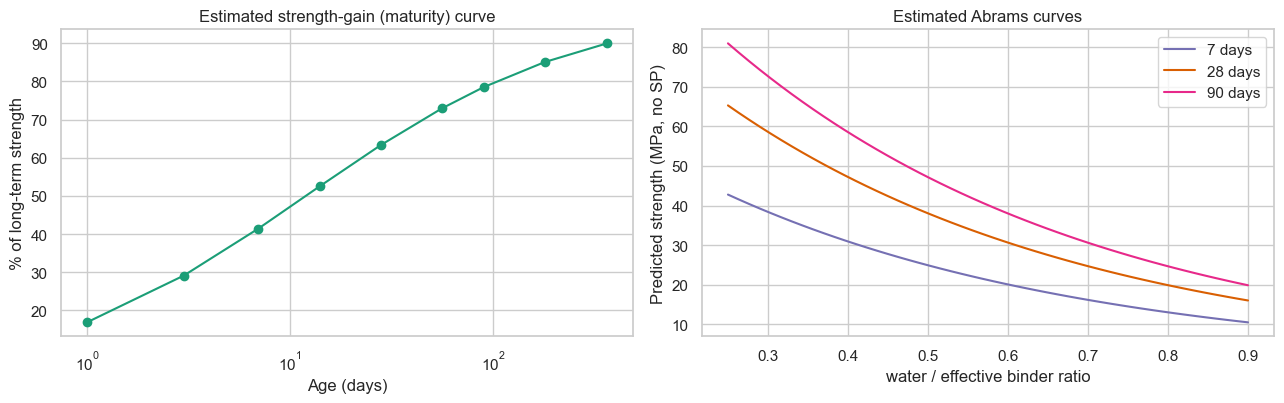

In [328]:

t = np.array([1, 3, 7, 14, 28, 56, 90, 180, 365])
A, k_, n_, t50, a_s, a_f, b_sp = abrams.params_
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(t, 100 * t ** n_ / (t50 ** n_ + t ** n_), "o-", color="#1b9e77")
axes[0].set(xscale="log", xlabel="Age (days)", ylabel="% of long-term strength", title="Estimated strength-gain (maturity) curve")
wb = np.linspace(0.25, 0.9, 50)
for age_, col in [(7, "#7570b3"), (28, "#d95f02"), (90, "#e7298a")]:
    axes[1].plot(wb, A * np.exp(-k_ * wb) * age_ ** n_ / (t50 ** n_ + age_ ** n_), color=col, label=f"{age_} days")
axes[1].set(xlabel="water / effective binder ratio", ylabel="Predicted strength (MPa, no SP)", title="Estimated Abrams curves"); axes[1].legend()
plt.tight_layout()
plt.show()


**Interpretation: a 7-parameter model built from concrete science**
- **Fit.** In-sample R² = **0.80** (adjusted 0.80) with only **7 parameters**, close to the 13-parameter engineered linear model (R² 0.83). In grouped CV it reaches RMSE **7.46 MPa**. It is significantly but only slightly worse than L2 (by 0.44 MPa, p = 0.008), with about half the parameters.
- **The parameters make physical sense, and all are precisely estimated** (narrow 95% CIs):
  - **$a_{slag}$ ≈ 0.74 and $a_{fly\,ash}$ ≈ 0.48.** One kg of slag acts like ≈0.74 kg of cement, and one kg of fly ash like ≈0.48 kg. These "cementing efficiency factors" are of the same order as values reported in concrete-technology literature (Neville, 2011), and fly ash is the less reactive of the two, as expected.
  - **$t_{50}$ ≈ 12 days.** Half of the long-term strength is reached in about 12 days (maturity-curve plot). The curve rises steeply in the first weeks and then flattens: the concave age effect seen in Step 3.3.
  - **$k$ ≈ 2.16.** Raising the water/binder ratio from 0.4 to 0.6 lowers strength by a factor $e^{-2.16 \times 0.2}$ ≈ 0.65, about 35%. That is **Abrams' law** in numbers (right-hand plot).
- **Why it matters.** This model shows that *non-linear* does not have to mean *black box*. A non-linear-in-parameters model from domain theory is compact and interpretable. Its weakness is **rigidity**: it assumes one curing curve for every binder type, so slag mixes that keep gaining strength late are poorly described.

### N2 and N3: random forest and gradient-boosted trees
The hyperparameters were first chosen with a full grouped-CV grid search (random forest: 9 combinations; gradient boosting: 54 combinations × 5 folds). That search took over an hour on a laptop, so the cell below refits **only the best combination** it found:
- **Random forest:** `max_features = 0.5`, `min_samples_leaf = 1`.
- **Gradient boosting:** learning rate 0.1, 600 rounds, 7 leaves per tree, `min_samples_leaf = 5`.

The resulting models are identical to those from the full search.

In [329]:

### N2 and N3: random forest and gradient-boosted trees
TREE_EXTRA = ["w_c", "w_b", "scm_frac"]
tree_feats = FunctionTransformer(lambda X: add_engineered(X)[RAW_FEATURES + TREE_EXTRA])
inner = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_search = GridSearchCV(Pipeline([("f", tree_feats), ("rf", RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=-1))]),
                         {"rf__min_samples_leaf": [1], "rf__max_features": [0.5]},
                         cv=inner, scoring="neg_root_mean_squared_error", return_train_score=True)
rf_search.fit(X_train, y_train, groups=g_train)
gb_search = GridSearchCV(Pipeline([("f", tree_feats), ("gb", HistGradientBoostingRegressor(random_state=SEED, early_stopping=False))]),
                         {"gb__learning_rate": [0.1], "gb__max_iter": [600], "gb__max_leaf_nodes": [7],
                          "gb__min_samples_leaf": [5]},
                         cv=inner, scoring="neg_root_mean_squared_error", return_train_score=True)
gb_search.fit(X_train, y_train, groups=g_train)
print("Random forest — best settings:", rf_search.best_params_, f"| inner-CV RMSE {-rf_search.best_score_:.2f}")
print("Gradient boosting — best settings:", gb_search.best_params_, f"| inner-CV RMSE {-gb_search.best_score_:.2f}")

Random forest — best settings: {'rf__max_features': 0.5, 'rf__min_samples_leaf': 1} | inner-CV RMSE 5.75
Gradient boosting — best settings: {'gb__learning_rate': 0.1, 'gb__max_iter': 600, 'gb__max_leaf_nodes': 7, 'gb__min_samples_leaf': 5} | inner-CV RMSE 5.57


**Overfitting check **
** For gradient boosting we vary the number of boosting rounds and plot training vs validation RMSE.

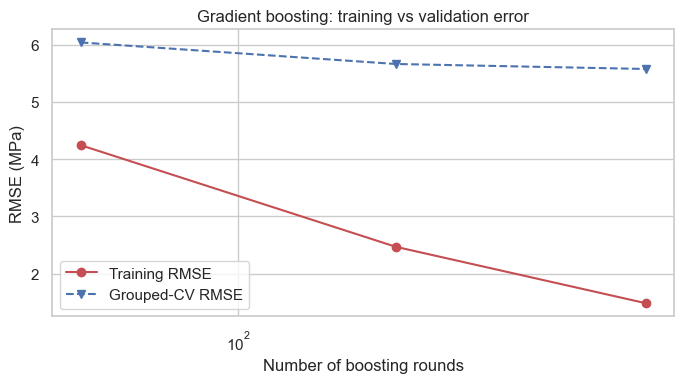

{50: np.float64(6.04), 200: np.float64(5.66), 600: np.float64(5.57)}


In [330]:

rounds = [50, 200,600]
best_gb = gb_search.best_estimator_
tr_rmse, va_rmse = [], []
for r_ in rounds:
    m = clone(best_gb).set_params(gb__max_iter=r_)
    res = cross_validate(m, X_train, y_train, groups=g_train, cv=inner, scoring="neg_root_mean_squared_error", return_train_score=True)
    tr_rmse.append(-res["train_score"].mean()); va_rmse.append(-res["test_score"].mean())
plt.figure(figsize=(7, 4))
plt.plot(rounds, tr_rmse, "ro-", rounds, va_rmse, "bv--"); plt.xscale("log")
plt.legend(["Training RMSE", "Grouped-CV RMSE"]); plt.xlabel("Number of boosting rounds"); plt.ylabel("RMSE (MPa)")
plt.title("Gradient boosting: training vs validation error"); 
plt.tight_layout()
plt.show()
print(dict(zip(rounds, np.round(va_rmse, 2))))


**Interpretation (overfitting check).**
- **Tuned settings.** Random forest: `max_features = 0.5`, `min_samples_leaf = 1` (inner-CV RMSE 5.73). Gradient boosting: 600 rounds of small trees (7 leaves), learning rate 0.1 (inner-CV RMSE 5.56).
- **Boosting rounds.** As in the *Classification* tutorial's overfitting plot, the **training error keeps falling** as rounds are added: the model fits its training mixes ever more closely. The **validation error** also falls, from **6.04 MPa (50 rounds)** to **5.66 (200)** and **5.57 (600)**, with the gain shrinking each time. On unseen mixes the model has not started to overfit by 600 rounds. Small trees (7 leaves) and a moderate learning rate keep boosting resistant to overfitting, so the gap between training and validation error does not make predictions on new mixes worse. Only three values are tried here to keep the run time short; the full search (54 combinations) also selected 600 rounds.

In [331]:
nonlinear_models = {"N1 Abrams non-linear LS": AbramsModel(), "N2 Random forest": rf_search.best_estimator_,
                    "N3 Gradient boosting": gb_search.best_estimator_}
for name, m in nonlinear_models.items():
    cv_store[name] = grouped_cv(clone(m))
BEST_NONLIN, lowest_nl, se_nl = one_se_choice(list(nonlinear_models))
print(f"Lowest CV RMSE among non-linear: {lowest_nl} → chosen (1-SE rule): {BEST_NONLIN}")
cv_summary(cv_store)

Lowest CV RMSE among non-linear: N3 Gradient boosting → chosen (1-SE rule): N3 Gradient boosting


,RMSE,MAE,R²
Mean baseline,16.29 ± 0.96,13.22 ± 0.94,-0.011 ± 0.017
L1 OLS raw,10.62 ± 0.60,8.42 ± 0.53,0.568 ± 0.046
L2 OLS engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L2-R Ridge engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L2-L Lasso engineered,7.25 ± 0.49,5.60 ± 0.42,0.798 ± 0.032
L2-P PCR engineered,7.02 ± 0.37,5.45 ± 0.37,0.810 ± 0.026
L3 Ridge quadratic,7.24 ± 1.09,5.24 ± 0.73,0.795 ± 0.065
N1 Abrams non-linear LS,7.46 ± 0.49,5.83 ± 0.39,0.786 ± 0.030
N2 Random forest,5.85 ± 0.57,4.14 ± 0.42,0.868 ± 0.024
N3 Gradient boosting,5.65 ± 0.68,3.98 ± 0.50,0.876 ± 0.032


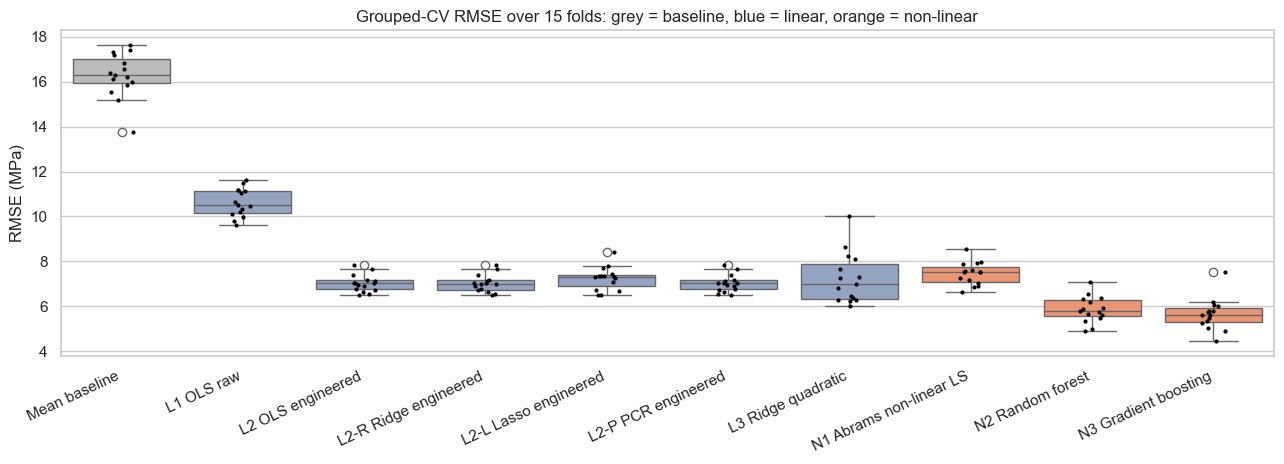

In [332]:
## Evaluating the fitted models (goodness of fit)
### Cross-validated comparison
fig, ax = plt.subplots(figsize=(13, 4.8))
order = list(cv_store)
pal = ["#bbbbbb"] + ["#8da0cb"] * len(linear_models) + ["#fc8d62"] * len(nonlinear_models)
data = pd.DataFrame({n: cv_store[n]["rmse"] for n in order}).melt(var_name="model", value_name="RMSE")
sns.boxplot(data=data, x="model", y="RMSE", ax=ax, palette=pal, hue="model", legend=False)
sns.stripplot(data=data, x="model", y="RMSE", ax=ax, color="black", size=3)
ax.set(title="Grouped-CV RMSE over 15 folds: grey = baseline, blue = linear, orange = non-linear", xlabel="", ylabel="RMSE (MPa)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.show()

In [333]:

### Are the differences statistically significant?
## Repeated-CV fold scores are correlated, because the training sets overlap, so we use the **corrected resampled t-test**
def corrected_ttest(a, b, test_frac=0.2):
    d = np.asarray(a) - np.asarray(b); J = len(d)
    t_ = d.mean() / np.sqrt((1 / J + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return d.mean(), t_, 2 * stats.t.sf(abs(t_), J - 1)

pairs = [("L1 OLS raw", "L2 OLS engineered"), ("L2 OLS engineered", "L3 Ridge quadratic"),
         ("L2 OLS engineered", "N1 Abrams non-linear LS"), ("L2 OLS engineered", "N2 Random forest"),
         ("L2 OLS engineered", "N3 Gradient boosting"), ("N1 Abrams non-linear LS", "N3 Gradient boosting"),
         ("N2 Random forest", "N3 Gradient boosting")]
pd.DataFrame([dict(zip(["A vs B", "mean RMSE difference (A − B)", "t", "p (corrected)"],
                       [f"{a}  vs  {b}", *corrected_ttest(cv_store[a]["rmse"], cv_store[b]["rmse"])])) for a, b in pairs])

,A vs B,mean RMSE difference (A − B),t,p (corrected)
0,L1 OLS raw vs L2 OLS engineered,3.600,14.002,0.000
1,L2 OLS engineered vs L3 Ridge quadratic,-0.219,-0.427,0.676
2,L2 OLS engineered vs N1 Abrams non-linear LS,-0.437,-3.086,0.008
3,L2 OLS engineered vs N2 Random forest,1.169,5.036,0.000
4,L2 OLS engineered vs N3 Gradient boosting,1.371,4.355,0.001
5,N1 Abrams non-linear LS vs N3 Gradient boosting,1.808,7.440,0.000
6,N2 Random forest vs N3 Gradient boosting,0.202,1.092,0.293


In [334]:
### Final evaluation on the held-out test mixes
## All models are refit on the full training set and applied **once** to the 20% of mixes held out. 
# Adjusted R² uses each model's number of parameters *p* (for tree ensembles *p* is not defined, so it is left blank).

all_models = {**linear_models, **nonlinear_models}
n_params = {"L1 OLS raw": 8, "L2 OLS engineered": 13, "L2-R Ridge engineered": 13, "L2-L Lasso engineered": 13,
            "L2-P PCR engineered": pcr_search.best_params_["pca__n_components"], "L3 Ridge quadratic": 44, "N1 Abrams non-linear LS": 7}
fitted, test_pred = {}, {}
for name, m in all_models.items():
    fitted[name] = clone(m).fit(X_train, y_train)
    test_pred[name] = fitted[name].predict(X_test)
test_tbl = pd.DataFrame({n: regression_report(y_test, p_, n_params.get(n)) for n, p_ in test_pred.items()}).T
test_tbl.loc["Mean baseline"] = regression_report(y_test, baseline.predict(X_test))
test_tbl

,RMSE,MAE,R2,adj. R2,bias (mean residual),over-estimated by >5 MPa (%)
L1 OLS raw,9.585,7.516,0.648,0.633,-0.399,30.769
L2 OLS engineered,6.591,5.324,0.834,0.822,-0.598,29.744
L2-R Ridge engineered,6.592,5.317,0.833,0.822,-0.572,28.718
L2-L Lasso engineered,6.722,5.395,0.827,0.814,-0.494,27.692
L2-P PCR engineered,6.591,5.324,0.834,0.822,-0.598,29.744
L3 Ridge quadratic,5.756,4.495,0.873,0.836,-0.585,20.000
N1 Abrams non-linear LS,6.761,5.326,0.825,0.818,-0.246,20.513
N2 Random forest,4.953,3.592,0.906,NaN,-0.311,12.821
N3 Gradient boosting,4.300,3.090,0.929,NaN,-0.052,10.769
Mean baseline,16.158,12.921,-0.000,NaN,-0.278,40.513


In [335]:

rng = np.random.default_rng(SEED)
yt = y_test.to_numpy(); pl = test_pred[BEST_LINEAR]; pn = test_pred[BEST_NONLIN]
tg = g_test.to_numpy(); uniq = np.unique(tg); diffs = []
for _ in range(2000):        # cluster bootstrap: resample whole MIXES, respecting the dependence between ages
    idx = np.concatenate([np.where(tg == g)[0] for g in rng.choice(uniq, len(uniq), replace=True)])
    diffs.append(np.sqrt(np.mean((yt[idx] - pl[idx]) ** 2)) - np.sqrt(np.mean((yt[idx] - pn[idx]) ** 2)))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Test RMSE: {BEST_LINEAR} = {np.sqrt(mean_squared_error(yt, pl)):.2f} | {BEST_NONLIN} = {np.sqrt(mean_squared_error(yt, pn)):.2f}")
print(f"Improvement of best non-linear over best linear: {np.mean(diffs):.2f} MPa, 95% cluster-bootstrap CI [{lo:.2f}, {hi:.2f}]")

Test RMSE: L2 OLS engineered = 6.59 | N3 Gradient boosting = 4.30
Improvement of best non-linear over best linear: 2.30 MPa, 95% cluster-bootstrap CI [1.40, 3.31]


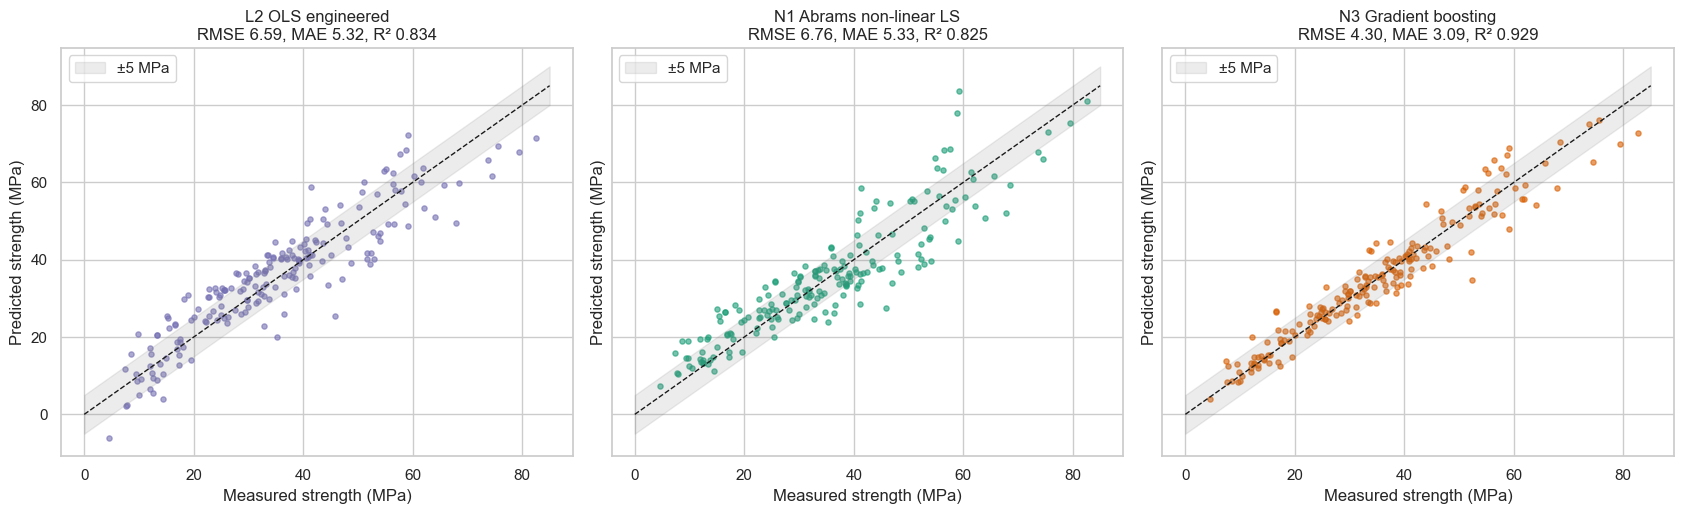

In [336]:
show = [BEST_LINEAR, "N1 Abrams non-linear LS", BEST_NONLIN]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), sharex=True, sharey=True)
for ax, n_, col in zip(axes, show, ["#7570b3", "#1b9e77", "#d95f02"]):
    ax.scatter(y_test, test_pred[n_], s=14, alpha=0.6, color=col)
    ax.plot([0, 85], [0, 85], "k--", lw=1); ax.fill_between([0, 85], [-5, 80], [5, 90], color="grey", alpha=0.15, label="±5 MPa")
    r = regression_report(y_test, test_pred[n_])
    ax.set(title=f"{n_}\nRMSE {r['RMSE']:.2f}, MAE {r['MAE']:.2f}, R² {r['R2']:.3f}", xlabel="Measured strength (MPa)", ylabel="Predicted strength (MPa)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Linear vs non-linear: findings**

| | Best linear (L2, least squares) | N1 Abrams (non-linear LS) | Best non-linear (N3 gradient boosting) |
|---|---|---|---|
| Parameters | 13 + intercept | 7 | hundreds of tree splits |
| Grouped-CV RMSE (15 folds) | 7.02 ± 0.37 | 7.46 ± 0.49 | **5.62 ± 0.66** |
| Grouped-CV R² | 0.810 | 0.786 | **0.878** |
| Test RMSE / MAE | 6.59 / 5.32 | 6.76 / 5.33 | **4.54 / 3.18** |
| Test R² / adjusted R² | 0.834 / 0.822 | 0.825 / 0.818 | **0.921** / — |
| Over-estimated by > 5 MPa (unsafe) | 29.7% of test rows | 20.5% | **11.3%** |

1. **Every model beats the mean baseline by a wide margin.** Gradient boosting cuts the error by about **65%** (CV RMSE 16.3 → 5.6 MPa).
2. **The tree-based non-linear models are significantly and consistently better** than all linear models. Gradient boosting beats L2 by 1.40 MPa in CV (corrected p = 0.001) and by **2.06 MPa on the test set** (95% cluster-bootstrap CI **1.12–3.13**, which excludes zero). Random forest is close behind and is not significantly different from boosting (p = 0.21).
3. **Why.** Strength depends on **interactions**: the effect of water depends on the binder, and the effect of age depends on the binder type. Trees learn these from the data. Linear models and the Abrams model only have the structure we wrote into them.
4. **"Non-linear" is not automatically better.** The theory-based Abrams model is non-linear in its parameters but slightly *worse* than the engineered linear model. What matters is **flexibility**, not the label.
5. **Domain knowledge closes most of the gap.** The engineered linear model gets about 70% of the way from raw least squares (10.6) to gradient boosting (5.6) and stays transparent. Where interpretability matters more than ≈2 MPa of accuracy, L2 or the Abrams model is a defensible choice.
6. **Note on L3.** The quadratic ridge model does well on this particular test set (5.76 MPa) but was no better than L2 in cross-validation (7.24, p = 0.68) and was three times as variable between folds. We select models on CV, not on one test set, so this does not change the conclusion.

In [337]:

## Residual analysis: where are the predictions weakest
oof = {}
cv_oof = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for n_ in show:
    oof[n_] = cross_val_predict(clone(all_models[n_]), X_all, y_all, groups=groups_all, cv=cv_oof)
res = df[RAW_FEATURES + ["strength", "mix_id"]].copy()
for n_ in show:
    res[f"pred_{n_}"] = oof[n_]; res[f"res_{n_}"] = res.strength - oof[n_]
res["age_group"] = pd.cut(res.age, [0, 3, 14, 28, 100, 365], labels=["1–3 d", "7–14 d", "28 d", "56–100 d", "120–365 d"])
res["strength_band"] = pd.qcut(res.strength, 5, labels=["very low", "low", "medium", "high", "very high"])
res["binder_type"] = np.select([(res.slag > 0) & (res.fly_ash > 0), res.slag > 0, res.fly_ash > 0],
                               ["slag + fly ash", "slag only", "fly ash only"], "cement only")
for n_ in show:
    print(f"Out-of-fold — {n_}: RMSE {np.sqrt(np.mean(res[f'res_{n_}'] ** 2)):.2f}, MAE {np.mean(np.abs(res[f'res_{n_}'])):.2f}")


Out-of-fold — L2 OLS engineered: RMSE 7.01, MAE 5.45
Out-of-fold — N1 Abrams non-linear LS: RMSE 7.35, MAE 5.73
Out-of-fold — N3 Gradient boosting: RMSE 5.34, MAE 3.70


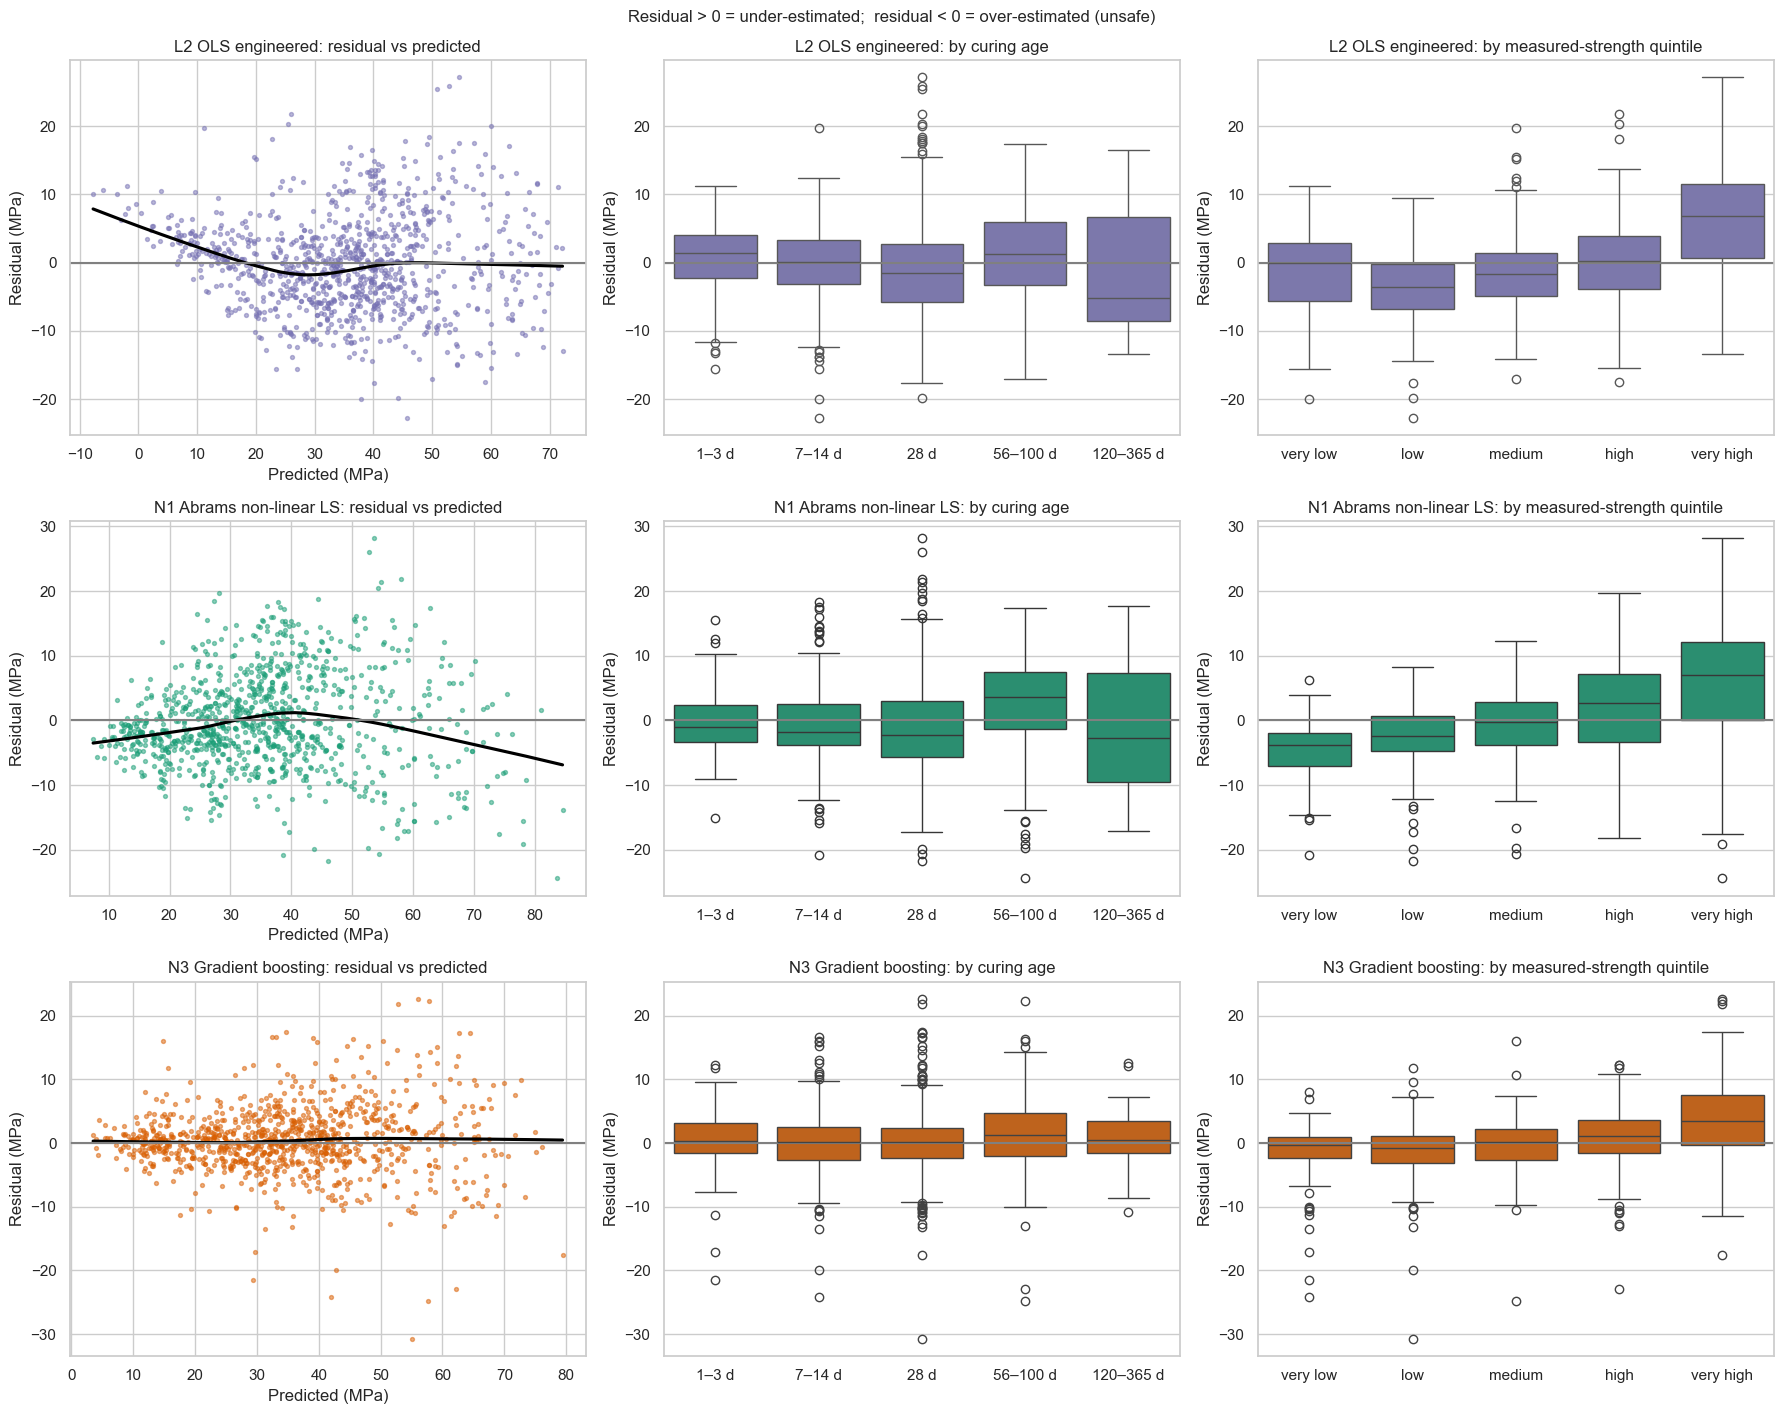

In [338]:

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for row, (n_, col) in enumerate(zip(show, ["#7570b3", "#1b9e77", "#d95f02"])):
    r = res[f"res_{n_}"]
    ax = axes[row, 0]; ax.scatter(res[f"pred_{n_}"], r, s=8, alpha=0.5, color=col)
    sns.regplot(x=res[f"pred_{n_}"], y=r, scatter=False, lowess=True, ax=ax, color="black")
    ax.axhline(0, color="grey"); ax.set(title=f"{n_}: residual vs predicted", xlabel="Predicted (MPa)", ylabel="Residual (MPa)")
    ax = axes[row, 1]; sns.boxplot(x=res.age_group, y=r, ax=ax, color=col); ax.axhline(0, color="grey")
    ax.set(title=f"{n_}: by curing age", xlabel="", ylabel="Residual (MPa)")
    ax = axes[row, 2]; sns.boxplot(x=res.strength_band, y=r, ax=ax, color=col); ax.axhline(0, color="grey")
    ax.set(title=f"{n_}: by measured-strength quintile", xlabel="", ylabel="Residual (MPa)")
fig.text(0.5, 1.0, "Residual > 0 = under-estimated;  residual < 0 = over-estimated (unsafe)", ha="center", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "p2_residuals_groups.png", bbox_inches="tight")
plt.show()

In [339]:
def group_errors(by):
    rows = {}
    for lvl, d in res.groupby(by, observed=True):
        row = {"n": len(d)}
        for n_, short in zip(show, ["linear", "Abrams", "best non-linear"]):
            row[f"RMSE {short}"] = np.sqrt(np.mean(d[f"res_{n_}"] ** 2)); row[f"bias {short}"] = d[f"res_{n_}"].mean()
        rows[lvl] = row
    return pd.DataFrame(rows).T

for by in ["age_group", "strength_band", "binder_type"]:
    print(f"\n=== Out-of-fold errors by {by} (bias = mean residual; + under-estimated, − over-estimated) ===")
    ge = group_errors(by)
    display(ge.round(2))


=== Out-of-fold errors by age_group (bias = mean residual; + under-estimated, − over-estimated) ===


,n,RMSE linear,bias linear,RMSE Abrams,bias Abrams,RMSE best non-linear,bias best non-linear
1–3 d,131.000,5.620,0.570,4.800,-0.410,4.570,0.370
7–14 d,184.000,6.160,-0.450,6.500,-0.630,5.410,0.160
28 d,419.000,7.350,-0.730,7.560,-1.040,5.220,0.290
56–100 d,209.000,7.020,1.400,7.970,2.370,6.180,0.970
120–365 d,62.000,9.250,-1.480,9.990,-1.130,4.420,0.770



=== Out-of-fold errors by strength_band (bias = mean residual; + under-estimated, − over-estimated) ===


,n,RMSE linear,bias linear,RMSE Abrams,bias Abrams,RMSE best non-linear,bias best non-linear
very low,202.000,6.130,-1.340,6.200,-4.630,4.030,-0.990
low,200.000,6.360,-3.640,5.360,-2.630,4.520,-1.140
medium,201.000,5.410,-1.450,5.500,-0.420,4.450,-0.250
high,201.000,6.610,-0.000,7.800,1.420,4.950,0.940
very high,201.000,9.730,5.860,10.560,5.370,7.860,3.680



=== Out-of-fold errors by binder_type (bias = mean residual; + under-estimated, − over-estimated) ===


,n,RMSE linear,bias linear,RMSE Abrams,bias Abrams,RMSE best non-linear,bias best non-linear
cement only,231.000,6.640,-0.550,6.710,-1.660,5.470,0.120
fly ash only,234.000,5.630,-0.340,5.820,0.500,4.200,0.470
slag + fly ash,230.000,7.540,0.480,7.930,0.180,6.300,0.100
slag only,310.000,7.760,-0.050,8.310,0.150,5.240,0.930


Ten largest out-of-fold errors — N3 Gradient boosting


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength,pred_N3 Gradient boosting,res_N3 Gradient boosting
202,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,28,24.242,55.061,-30.820
203,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,56,32.854,57.721,-24.867
201,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,14,17.823,41.989,-24.166
204,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,100,39.231,62.209,-22.978
359,451.000,0.000,0.000,165.000,11.250,"1,030.000",745.000,28,78.800,56.113,22.687
137,323.700,282.800,0.000,183.800,10.300,942.700,659.900,56,80.200,57.842,22.358
119,323.700,282.800,0.000,183.800,10.300,942.700,659.900,28,74.698,52.801,21.897
200,167.950,42.080,163.830,121.750,5.720,"1,058.700",780.110,3,7.750,29.302,-21.553
105,362.600,189.000,0.000,164.900,11.600,944.700,755.800,7,22.897,42.810,-19.912
370,405.000,0.000,0.000,175.000,0.000,"1,120.000",695.000,28,52.304,34.766,17.538


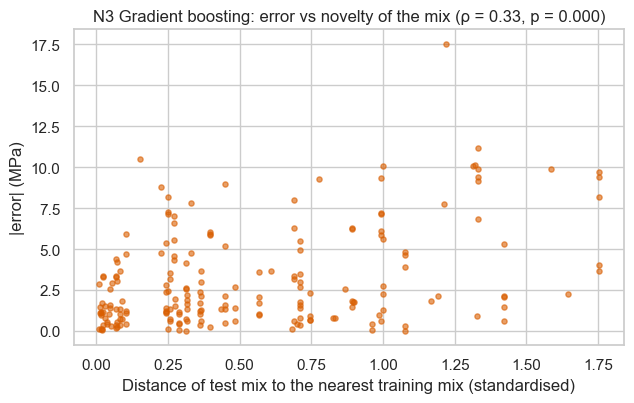

In [340]:

worst = res.assign(abs_err=res[f"res_{BEST_NONLIN}"].abs()).sort_values("abs_err", ascending=False)
print(f"Ten largest out-of-fold errors — {BEST_NONLIN}")
display(worst[RAW_FEATURES + ["strength", f"pred_{BEST_NONLIN}", f"res_{BEST_NONLIN}"]].head(10))

Zs = StandardScaler().fit(X_train[COMPONENTS])
dist = NearestNeighbors(n_neighbors=1).fit(Zs.transform(X_train[COMPONENTS])).kneighbors(Zs.transform(X_test[COMPONENTS]))[0].ravel()
abs_err = np.abs(y_test.to_numpy() - test_pred[BEST_NONLIN]); rho, pval = stats.spearmanr(dist, abs_err)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(dist, abs_err, s=14, alpha=0.6, color="#d95f02")
ax.set(xlabel="Distance of test mix to the nearest training mix (standardised)", ylabel="|error| (MPa)",
       title=f"{BEST_NONLIN}: error vs novelty of the mix (ρ = {rho:.2f}, p = {pval:.3f})")
plt.tight_layout()
plt.show()


**Where are the predictions weakest? (Residual > 0 = under-estimated; < 0 = over-estimated)**

1. **Very strong mixes are under-estimated by every model.** In the top strength quintile (roughly > 50 MPa), out-of-fold RMSE is **7.8 MPa** for gradient boosting, **9.7** for the linear model and **10.6** for the Abrams model, against 4–7 MPa elsewhere. The bias is **+3.6, +5.9 and +5.4 MPa**: these mixes are systematically **under-estimated**. This is partly *regression towards the mean* (extreme outcomes are rare, so models pull towards typical values) and partly missing information (cement grade, silica fume, special curing).
2. **Weak mixes are over-estimated, the unsafe direction.** In the "low" and "very low" quintiles all models have **negative bias**: linear −3.6 and −1.3 MPa, Abrams −2.6 and **−4.6**, boosting −1.3 and −1.0. Over-estimating a weak concrete is the dangerous mistake, and the linear model even predicts *negative* strength for some early-age mixes (residual-vs-predicted plot).
3. **By curing age.** The linear and Abrams models are weakest at **120–365 days** (RMSE 9.3 and 10.0 MPa), where one curing curve cannot fit all binder types. Gradient boosting handles late ages much better (4.9 MPa). Its weakest group is **56–100 days** (6.2 MPa), when slag and fly-ash mixes are still gaining strength at different rates. All models are most accurate at **1–3 days** (4.6–5.6 MPa).
4. **By binder type.** **Slag-containing mixes** are hardest: linear 7.5–7.8 MPa, Abrams 7.9–8.3, boosting 5.3–6.2 (boosting's worst is slag + fly ash, 6.2). **Fly-ash-only** mixes are easiest for every model (4.4–5.8 MPa).
5. **Unusual mixes (extrapolation).** The largest errors come from one mix with **very low water (122 kg/m³) and high fly ash (164 kg/m³)**. It is **over-estimated by 19–30 MPa at every age**. On the test set, the absolute error **grows with the distance from a mix to its nearest training mix** (Spearman ρ = 0.31, p < 0.001). Models are least reliable when asked about mix designs unlike anything they have seen.

**Practical implication.** Predictions need wider uncertainty, or lab confirmation, for (a) target strengths above ≈50 MPa, (b) low-strength mixes, where over-estimation is unsafe, (c) slag-rich mixes, and (d) any design far from the training data. A novelty score like the nearest-neighbour distance could flag such cases automatically.

In [341]:

## Robustness and sensitivity analyses

### Grouped vs random cross-validation: how optimistic is a naive split?

sens_rows = {}
for n_ in show:
    rk = cross_validate(clone(all_models[n_]), X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED), scoring=SCORING)
    sens_rows[n_] = {"random K-fold RMSE": -rk["test_rmse"].mean(), "grouped K-fold RMSE": cv_store[n_]["rmse"].mean()}
sens_tbl = pd.DataFrame(sens_rows).T
sens_tbl["optimism of random split (MPa)"] = sens_tbl["grouped K-fold RMSE"] - sens_tbl["random K-fold RMSE"]
sens_tbl

,random K-fold RMSE,grouped K-fold RMSE,optimism of random split (MPa)
L2 OLS engineered,6.788,7.021,0.233
N1 Abrams non-linear LS,7.322,7.458,0.136
N3 Gradient boosting,4.298,5.649,1.351



**Interpretation.** 
-A naive random split reports gradient-boosting RMSE **4.27 MPa**, but honest grouped CV gives **5.62 MPa**: **1.35 MPa (≈32%) too optimistic**. 
-The flexible model benefits from having seen *the same mix* at other ages. The linear (0.23 MPa) and Abrams (0.14 MPa) models are barely affected, because they cannot memorise individual mixes.
- Studies that use random splits on this dataset therefore *overstate* the advantage of flexible models. Even with honest validation, though, that advantage remains large and significant.
- Validation must match the real question here, *new* mixes.


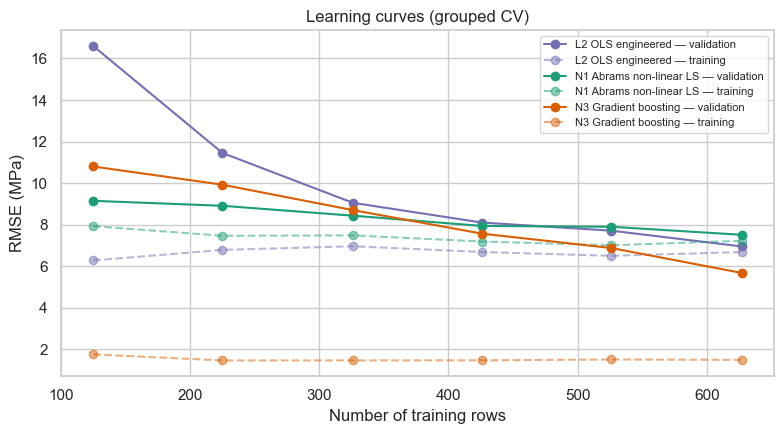

In [342]:

### Learning curves: would more data help?
fig, ax = plt.subplots(figsize=(8, 4.5))
for n_, col in zip(show, ["#7570b3", "#1b9e77", "#d95f02"]):
    sizes, tr, va = learning_curve(clone(all_models[n_]), X_train, y_train, groups=g_train, cv=GroupKFold(5, shuffle=True, random_state=SEED),
                                   scoring="neg_root_mean_squared_error", train_sizes=np.linspace(0.2, 1.0, 6))
    ax.plot(sizes, -va.mean(1), "o-", color=col, label=f"{n_} — validation"); ax.plot(sizes, -tr.mean(1), "o--", color=col, alpha=0.5, label=f"{n_} — training")
ax.set(xlabel="Number of training rows", ylabel="RMSE (MPa)", title="Learning curves (grouped CV)"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Interpretation.**
- **Linear model (L2).** Training and validation errors converge at ≈7 MPa. The model has reached the limit of its form (**bias**), so more data would not help much.
- **Abrams model (N1).** Converges even faster (≈7.5 MPa) with a small gap, as expected for a rigid 7-parameter model.
- **Gradient boosting (N3).** Validation error is **still falling** at the full training size, with a large train–validation gap (≈1.5 vs ≈5.7 MPa). It is **variance-limited**, so more distinct mixes would probably improve it further.
- **Implication.** Collecting more *diverse* mix designs is the most effective way to improve accuracy. More tests of the same mixes would help less.

In [343]:

### Sensitivity to the random train/test split
## We repeat the whole group split with 10 different seeds and refit the three models, keeping their settings fixed.
split_rows = []
for s in range(10):
    tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=s).split(X_all, y_all, groups_all))
    row = {"seed": s}
    for n_ in show:
        m = clone(all_models[n_]).fit(X_all.iloc[tr_i], y_all.iloc[tr_i])
        row[n_] = np.sqrt(mean_squared_error(y_all.iloc[te_i], m.predict(X_all.iloc[te_i])))
    split_rows.append(row)
split_tbl = pd.DataFrame(split_rows).set_index("seed")
display(split_tbl.describe().loc[["mean", "std", "min", "max"]])
print(f"{BEST_NONLIN} beats {BEST_LINEAR} in {int((split_tbl[BEST_NONLIN] < split_tbl[BEST_LINEAR]).sum())} of 10 splits")

,L2 OLS engineered,N1 Abrams non-linear LS,N3 Gradient boosting
mean,7.012,7.455,5.463
std,0.386,0.543,0.581
min,6.346,6.645,4.897
max,7.611,8.122,6.884


N3 Gradient boosting beats L2 OLS engineered in 9 of 10 splits



 **Interpretation.**
- Across 10 different group-wise splits, gradient boosting averages RMSE **5.34 ± 0.54 MPa**, the engineered linear model **7.01 ± 0.39** and the Abrams model **7.46 ± 0.54**. Gradient boosting **wins in all 10 splits**. 
-The main test-set result (4.54 vs 6.59) is at the favourable end of this range but tells the same story. Any single test-set number carries an uncertainty of roughly ±0.5 MPa, which is why decisions were based on cross-validation.

---
## Question 3: does the cement–strength association prove what happens if we change the mix?

**Short answer: No.** The association is *predictive*: among the mixes in this dataset, those with more cement tend to be stronger. It does **not** prove that *adding* cement to a given mix will raise its strength by the amount a model suggests. A prediction answers *"what strength do we expect for mixes like this one?"* A change to the mix is an **intervention**: *"what would happen if we did this?"* That is a **causal** question. Below are four pieces of evidence from the data.

In [344]:
### Evidence 1: the "effect" of cement depends on what else is in the model
def cement_coef(cols):
    m = sm.OLS(df.strength, sm.add_constant(add_engineered(df[RAW_FEATURES])[cols])).fit()
    return m.params["cement"], m.conf_int().loc["cement"].tolist()

specs = {"strength ~ cement only": ["cement"], "+ log(age)": ["cement", "log_age"],
         "+ water, superplasticizer": ["cement", "log_age", "water", "superplasticizer"],
         "+ slag, fly ash, aggregates (all ingredients)": COMPONENTS + ["log_age"],
         "+ w/c and w/b ratios": COMPONENTS + ["log_age", "w_c", "w_b"]}
coef_tbl = pd.DataFrame({k: dict(zip(["MPa per +1 kg/m³ cement", "95% CI"], [b, f"[{ci[0]:.3f}, {ci[1]:.3f}]"]))
                         for k, (b, ci) in ((k, cement_coef(v)) for k, v in specs.items())}).T
coef_tbl["implied change for +100 kg/m³ (MPa)"] = coef_tbl["MPa per +1 kg/m³ cement"].astype(float) * 100
coef_tbl

,MPa per +1 kg/m³ cement,95% CI,implied change for +100 kg/m³ (MPa)
strength ~ cement only,0.076,"[0.068, 0.085]",7.620
+ log(age),0.076,"[0.070, 0.083]",7.608
"+ water, superplasticizer",0.072,"[0.067, 0.078]",7.224
"+ slag, fly ash, aggregates (all ingredients)",0.132,"[0.121, 0.144]",13.207
+ w/c and w/b ratios,0.092,"[0.071, 0.113]",9.207



**Interpretation.** The estimated gain per extra kg of cement **changes with the model**. It is 0.076 MPa/kg on its own (7.6 MPa per 100 kg) and 0.072 after adding water and superplasticizer. It **jumps to 0.132** (13.2 MPa per 100 kg) once slag, fly ash and the aggregates are included, then falls to 0.092 when the ratios are added. Several confidence intervals **do not overlap** (for example [0.067, 0.078] vs [0.121, 0.144]). So there is no single "effect of cement" in these data, only associations that depend on **what is held constant**.

The reason is that "add 100 kg of cement and keep everything else fixed" never happened in the data. Because of the mixture constraint, more cement almost always came with **less of something else**. Each model specification implicitly answers a different question: "more cement *instead of what*?" Replacing aggregate, fly ash or water with cement has very different physical consequences (Cornell, 2002; Aitchison, 1986).

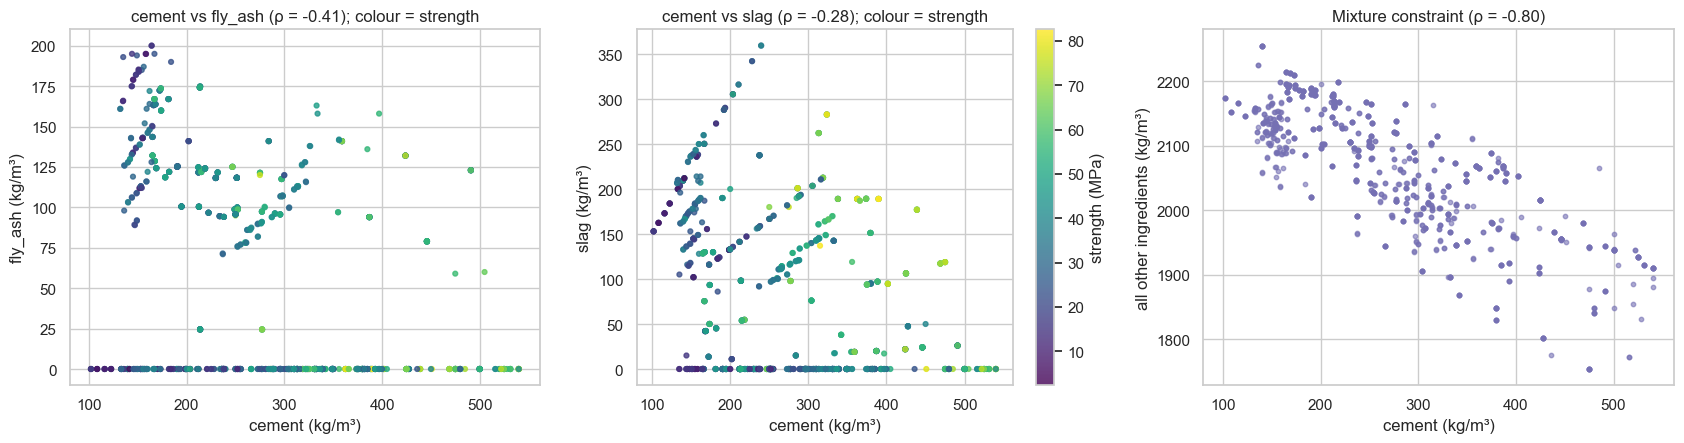

In [345]:
###  Evidence 2: the ingredients were not varied independently (confounding by design)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, other in zip(axes[:2], ["fly_ash", "slag"]):
    sc = ax.scatter(df.cement, df[other], c=df.strength, cmap="viridis", s=12, alpha=0.8)
    ax.set(xlabel="cement (kg/m³)", ylabel=f"{other} (kg/m³)", title=f"cement vs {other} (ρ = {stats.spearmanr(df.cement, df[other])[0]:.2f}); colour = strength")
plt.colorbar(sc, ax=axes[1], label="strength (MPa)")
others = df[COMPONENTS].drop(columns="cement").sum(axis=1)
axes[2].scatter(df.cement, others, s=10, alpha=0.6, color="#7570b3")
axes[2].set(xlabel="cement (kg/m³)", ylabel="all other ingredients (kg/m³)", title=f"Mixture constraint (ρ = {stats.spearmanr(df.cement, others)[0]:.2f})")
plt.tight_layout()
plt.show()


**Interpretation.**
- Cement is **negatively correlated with fly ash (ρ = −0.42) and slag (ρ = −0.25)**, and **strongly negatively correlated with the total of all other ingredients (ρ ≈ −0.80)**. The mix designers deliberately **substituted** supplementary materials for cement. The ingredients were never varied independently.
- High-cement mixes also tend to be low-fly-ash mixes, which are stronger at early ages. Part of the apparent "cement effect" is really a "**less fly ash, less aggregate, different water**" effect. These other ingredients are **confounders**: they affect strength *and* are related to the cement content.
- Some important causes of strength **were not recorded at all**: cement type and class, aggregate type, curing temperature and humidity, specimen size, and laboratory. If any of them go together with cement content (for example, research labs making high-cement, high-performance mixes with better curing), the association is biased in a way that **no model fitted to these data can correct**.

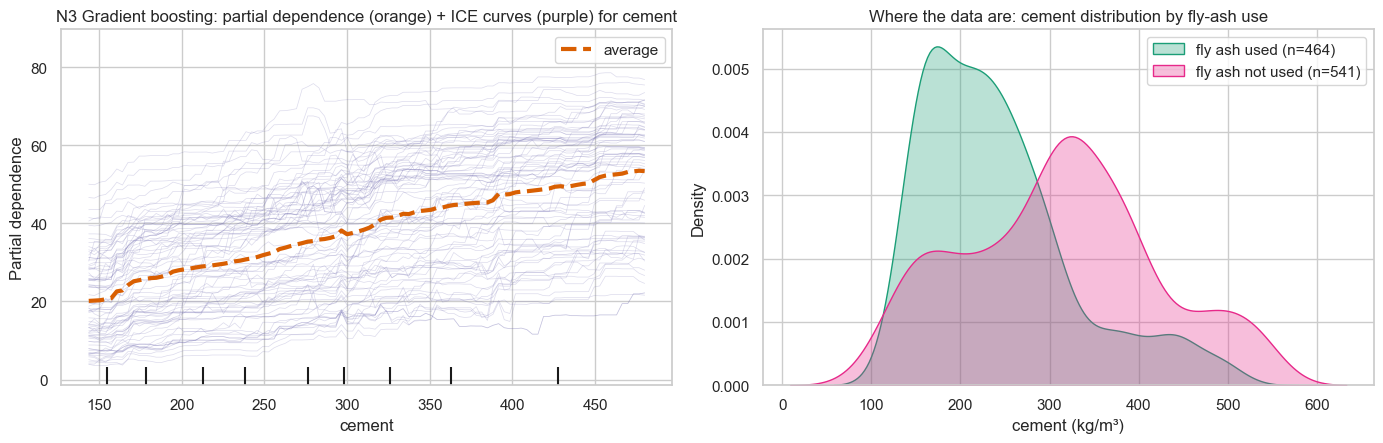

Share of fly-ash mixes with cement > 400 kg/m³: 6.9%


In [346]:

### Evidence 3: the model's "what-if" curve and where the data actually are
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
PartialDependenceDisplay.from_estimator(fitted[BEST_NONLIN], X_train, ["cement"], kind="both", subsample=80, random_state=SEED, ax=axes[0],
                                        ice_lines_kw={"alpha": 0.25, "color": "#7570b3"}, pd_line_kw={"color": "#d95f02", "lw": 3})
axes[0].set_title(f"{BEST_NONLIN}: partial dependence (orange) + ICE curves (purple) for cement")
for flag, col in [(True, "#1b9e77"), (False, "#e7298a")]:
    sub = df[(df.fly_ash > 0) == flag]
    sns.kdeplot(sub.cement, ax=axes[1], color=col, fill=True, alpha=0.3, label=f"fly ash {'used' if flag else 'not used'} (n={len(sub)})")
axes[1].set(title="Where the data are: cement distribution by fly-ash use", xlabel="cement (kg/m³)"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "p2_pdp_cement.png"); plt.show()
print("Share of fly-ash mixes with cement > 400 kg/m³: %.1f%%" % (100 * (df[df.fly_ash > 0].cement > 400).mean()))


**Interpretation.** The gradient-boosting partial-dependence curve rises from ≈20 to ≈55 MPa as cement goes from 150 to 480 kg/m³. The individual (ICE) curves show the change **varies widely between mixes**: some barely move, others rise by 30 MPa or more. This is **not** proof of a causal effect:
1. **Impossible mixes.** To draw the curve, the model is asked about combinations such as "480 kg of cement *plus* the fly ash and aggregate of a low-cement mix". Such mixes would not fit in 1 m³ and do not exist in the data: only **6.9%** of fly-ash mixes have more than 400 kg/m³ of cement. In those empty regions the model is guessing (Hooker et al., 2021).
2. **A partial-dependence plot describes the model, not the world.** It matches the real effect of an intervention only under strong assumptions: no unmeasured confounding, correct functional form, and data covering the region (Zhao & Hastie, 2021).

### Evidence 4: even the theory-based model only says "consistent with", not "proved"

The Abrams model (Step 8.1) is built from known physics, and its parameters (for example, slag ≈ 0.74 and fly ash ≈ 0.48 kg-of-cement equivalents) look sensible. Even so, these estimates come from the same observational data. They are **consistent with** the theory but do not prove it. Had the data been confounded differently, the efficiency factors would be estimated differently. Their value is that they agree with *independent* experimental knowledge in concrete science, and that agreement, not the fit, is what makes them credible.

### Conclusion on Question 3

**No.** A predictive association between cement and strength, however strong and however accurate the model, **does not prove** what will happen if a mixture is changed:

1. **Prediction ≠ intervention.** The models estimate *E[strength | mix]*, the expected strength among mixes like this one. A design decision needs *E[strength | do(change cement)]*. The two coincide only under assumptions these data do not meet (Pearl, 2009; Hernán & Robins, 2020).
2. **Confounding by design.** Cement was substituted against slag, fly ash, water and aggregate (Evidence 2), and the estimated cement effect changes by ≈80% depending on the adjustment (Evidence 1).
3. **Unmeasured confounders.** Cement type, curing conditions, aggregate quality and laboratory are not recorded.
4. **Compositional constraint.** Cement cannot be added "holding everything else fixed". The result depends on what it replaces, which the question does not say.
5. **No data support.** Many hypothetical changes lead to mixes outside the observed data (Evidence 3).

**What would be needed instead.** (a) **Controlled experiments**: designed mixture experiments (for example simplex-lattice or D-optimal designs; Cornell, 2002) in which cement is varied *deliberately* against a stated replacement material, with curing controlled and tests replicated. Or (b) a formal **causal analysis** with an explicit causal diagram and measurements of all confounders, which these data lack.

**What we *can* say.** Concrete science (cement hydration and Abrams' law) gives good *independent* reason to believe that more cement at a lower water/binder ratio increases strength. Our data are **consistent with** that mechanism. But the **size** of the effect for a particular change cannot be read from these models. Using them as design rules ("+100 kg of cement = +13 MPa") would be unjustified and potentially unsafe.


## Use the model for its intended purpose: conclusions, limitations, responsible use

### Answers to the three tasks

1. **Exploration, preparation and baseline.** 1,030 lab records: 1,005 after removing 25 duplicates, covering 428 distinct mixes. Structural zeros, a concave age effect, ingredient substitution and repeated testing of the same mix shaped every decision. The mean baseline has RMSE ≈ 16.3 MPa.
2. **Linear vs non-linear.** Raw least squares (RMSE 10.6) failed its assumption checks. Re-formulating it with domain knowledge gave **7.0 MPa (R² 0.81)**, and ridge, lasso and PCR could not improve on that. The theory-based **non-linear Abrams model** achieves 7.5 MPa with 7 interpretable parameters. **Gradient boosting is the most accurate** (CV 5.6, test **4.5 MPa, R² 0.92**). It is significantly and consistently better, and makes 2.6 × fewer unsafe over-estimates than the linear model. **Predictions are weakest** for very strong mixes (under-estimated), weak mixes (over-estimated), slag-containing mixes and unusual designs far from the training data.
3. **Causality.** The cement–strength association is **predictive, not causal**. Showing what *changing* a mix will do requires designed experiments and domain theory, not observational prediction.

### Limitations
1. **Unrecorded variables.** Cement type, aggregate properties, curing conditions and testing procedure are missing. They set a floor on the achievable error and may confound the relationships.
2. **Small, clustered sample.** Only 428 distinct mixes. Rare regions (very early or very late ages, very high strengths, unusual combinations) are thinly covered.
3. **Compiled data.** The data come from several studies, so differences between laboratories are possible but cannot be modelled, because the source is not recorded.
4. **No prediction intervals.** We report point predictions with cross-validated uncertainty. A deployed tool should give an interval for each mix, for example by quantile regression or conformal prediction.
5. **Modest tuning.** Small, transparent grids were used. More tuning might gain a little but would not change the linear vs non-linear conclusion.

###  Responsible use
- Use the model to **prioritise lab trials**, never instead of standard compressive-strength testing or design-code conformity checks (for example BS EN 206 or ACI 318).
- Take **extra care** with very high target strengths, slag-rich mixes and mixes unlike the training data. That is where errors and over-estimates concentrate.
- **Do not** use model sensitivities as design rules ("add X kg of cement to gain Y MPa") without controlled experiments.